# Part A

In [13]:
from google.colab import files
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from collections import Counter

# Upload CSV
uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

# Remove missing tweets
df = df.dropna(subset=['text']).copy()

# Download NLTK resources
for resource in ['punkt', 'punkt_tab', 'stopwords',
                 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

tokenizer = TweetTokenizer()
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

print("Dataset loaded successfully!")
print("Total tweets:", len(df))
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Saving Tweets.csv to Tweets (1).csv
Dataset loaded successfully!
Total tweets: 14640
Dataset shape: (14640, 15)
Columns: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 1.

NAIVE VS TWITTER TOKENIZATION

Original Tweet: @VirginAmerica What @dhepburn said.
Naive Tokens: ['@VirginAmerica', 'What', '@dhepburn', 'said.']
Twitter Tokens: ['@VirginAmerica', 'What', '@dhepburn', 'said', '.']
----------------------------------------------------------------------

Original Tweet: @VirginAmerica plus you've added commercials to the experience... tacky.
Naive Tokens: ['@VirginAmerica', 'plus', "you've", 'added', 'commercials', 'to', 'the', 'experience...', 'tacky.']
Twitter Tokens: ['@VirginAmerica', 'plus', "you've", 'added', 'commercials', 'to', 'the', 'experience', '...', 'tacky', '.']
----------------------------------------------------------------------

Original Tweet: @VirginAmerica I didn't today... Must mean I need to take another trip!
Naive Tokens: ['@VirginAmerica', 'I', "didn't", 'today...', 'Must', 'mean', 'I', 'need', 'to', 'take', 'another', 'trip!']
Twitter Tokens: ['@VirginAmerica', 'I', "didn't", 'today', '...', 'Must', 'mean', 'I', 'need', 'to', 

,Feature,Count
0,Handles,16507
1,Hashtags,3502
2,URLs,1211
3,Stretched Words,226
4,Emojis,811



Original vs Cleaned Tweets:


,text,cleaned_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercials to the experience...
2,@VirginAmerica I didn't today... Must mean I n...,i didnt today must mean i need to take another...
3,@VirginAmerica it's really aggressive to blast...,its really aggressive to blast obnoxious enter...
4,@VirginAmerica and it's a really big bad thing...,and its a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay 30 a flight for seats that...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...
7,@VirginAmerica Really missed a prime opportuni...,really missed a prime opportunity for men with...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i didntbut now i do d
9,"@VirginAmerica it was amazing, and arrived an ...",it was amazing and arrived an hour early youre...


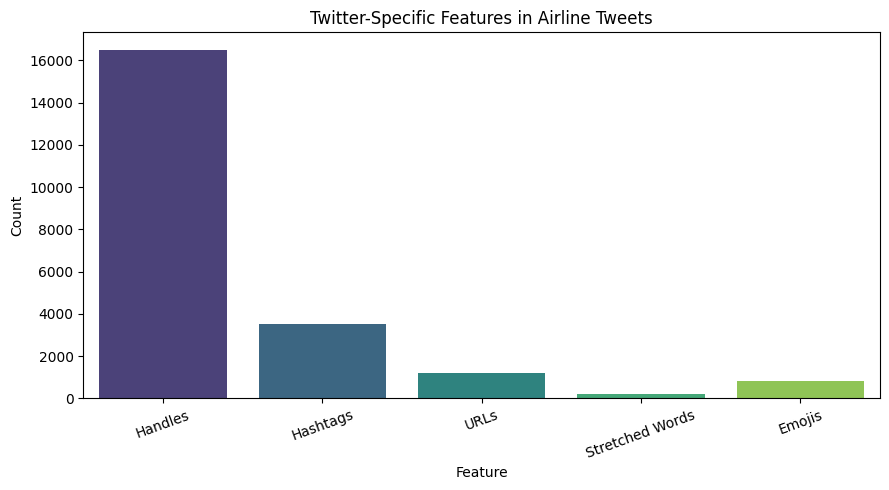

In [14]:
# Analyze actual tweets from CSV

print("NAIVE VS TWITTER TOKENIZATION")

for i, tweet in enumerate(df['text'].head(10)):

    naive = tweet.split()
    twitter = tokenizer.tokenize(tweet)

    print("\nOriginal Tweet:", tweet)
    print("Naive Tokens:", naive)
    print("Twitter Tokens:", twitter)
    print("-" * 70)


# Count Twitter-specific features
feature_counts = {
    'Handles': df['text'].str.count(r'@\w+').sum(),
    'Hashtags': df['text'].str.count(r'#\w+').sum(),
    'URLs': df['text'].str.count(r'https?://\S+|www\.\S+').sum(),
    'Stretched Words': df['text'].str.count(
        r'\b\w*(\w)\1{2,}\w*\b'
    ).sum(),
    'Emojis': df['text'].apply(
        lambda x: len(re.findall(
            r'[\U0001F300-\U0001FAFF]', str(x)
        ))
    ).sum()
}

feature_df = pd.DataFrame(
    list(feature_counts.items()),
    columns=['Feature', 'Count']
)

print("\nTwitter Feature Counts:")
display(feature_df)

# Cleaning function
def clean_tweet(text):

    text = str(text).lower()

    # Convert common emojis into words
    emoji_map = {
        '😡': ' angry ',
        '😠': ' angry ',
        '😢': ' sad ',
        '😭': ' sad ',
        '😊': ' happy ',
        '😍': ' love ',
        '❤️': ' love ',
        '👍': ' positive ',
        '👎': ' negative ',
        '✈️': ' airplane '
    }

    for emoji, label in emoji_map.items():
        text = text.replace(emoji, label)

    # Remove URLs and handles
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)

    # Keep hashtag words
    text = text.replace('#', '')

    # Normalize stretched words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)

    return text.strip()


df['cleaned_text'] = df['text'].apply(clean_tweet)

print("\nOriginal vs Cleaned Tweets:")
display(df[['text', 'cleaned_text']].head(10))

# Feature visualization
plt.figure(figsize=(9, 5))
sns.barplot(data=feature_df, x='Feature', y='Count',
            hue='Feature', palette='viridis', legend=False)
plt.title('Twitter-Specific Features in Airline Tweets')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 2.

Tweets containing negation: 2931

Original: status match program  i applied and its been three weeks  called and emailed with no response
Standard Stopword Removal: ['status', 'match', 'program', 'applied', 'three', 'weeks', 'called', 'emailed', 'response']
Improved Stopword Removal: ['status', 'match', 'program', 'applied', 'three', 'weeks', 'called', 'emailed', 'no', 'response']
------------------------------------------------------------

Original: hi i just bked a cool birthday trip with you but i cant add my elevate no cause i entered my middle name during flight booking problems  sad
Standard Stopword Removal: ['hi', 'bked', 'cool', 'birthday', 'trip', 'cant', 'add', 'elevate', 'cause', 'entered', 'middle', 'name', 'flight', 'booking', 'problems', 'sad']
Improved Stopword Removal: ['hi', 'bked', 'cool', 'birthday', 'trip', 'cant', 'add', 'elevate', 'no', 'cause', 'entered', 'middle', 'name', 'flight', 'booking', 'problems', 'sad']
-------------------------------------------------

/tmp/ipykernel_42381/3481091544.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['cleaned_text'].str.contains(


,Stage,Total Words,Vocabulary Size
0,Before Removal,238870,14635
1,After Removal,138837,14506


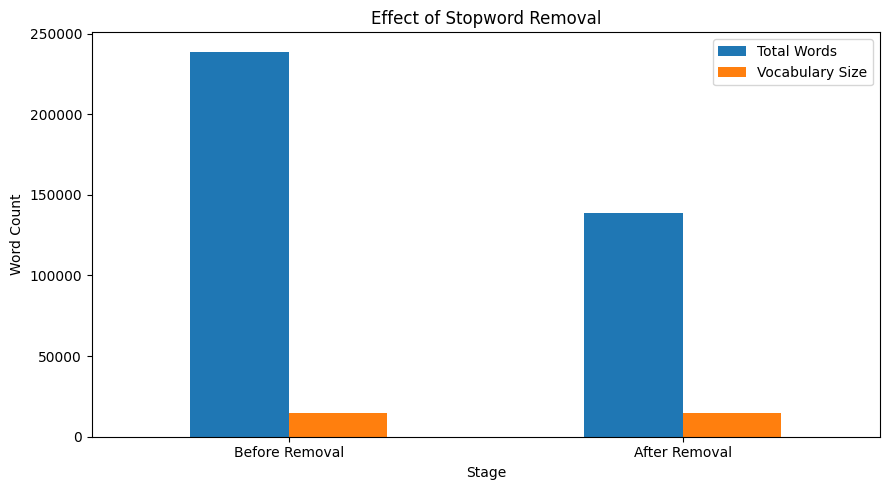

In [15]:
# Standard stopwords
stop_words = set(stopwords.words('english'))

# Preserve important negation words
final_stopwords = stop_words - {
    'not', 'no', 'nor', 'never'
}

# Find actual tweets containing negation
negation_tweets = df[
    df['cleaned_text'].str.contains(
        r'\b(not|no|nor|never)\b',
        regex=True
    )
]

print("Tweets containing negation:", len(negation_tweets))

# Compare standard and improved stopword removal
for tweet in negation_tweets['cleaned_text'].head(15):

    words = tweet.split()

    standard = [
        word for word in words
        if word not in stop_words
    ]

    improved = [
        word for word in words
        if word not in final_stopwords
    ]

    print("\nOriginal:", tweet)
    print("Standard Stopword Removal:", standard)
    print("Improved Stopword Removal:", improved)
    print("-" * 60)


# Apply final stopword removal to all tweets
df['tokens_without_stopwords'] = df['cleaned_text'].apply(
    lambda text: [
        word for word in text.split()
        if word not in final_stopwords
    ]
)

# Compare word counts
before = [
    word for text in df['cleaned_text']
    for word in text.split()
]

after = [
    word for tokens in df['tokens_without_stopwords']
    for word in tokens
]

comparison = pd.DataFrame({
    'Stage': ['Before Removal', 'After Removal'],
    'Total Words': [len(before), len(after)],
    'Vocabulary Size': [len(set(before)), len(set(after))]
})

display(comparison)

# Visualization
comparison.plot(
    x='Stage',
    y=['Total Words', 'Vocabulary Size'],
    kind='bar',
    figsize=(9, 5)
)

plt.title('Effect of Stopword Removal')
plt.ylabel('Word Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3.

STEMMING VS LEMMATIZATION


,tokens_without_stopwords,stemmed_tokens,lemmatized_tokens
0,[said],[said],[said]
1,"[plus, youve, added, commercials, experience, ...","[plu, youv, ad, commerci, experi, tacki]","[plus, youve, added, commercial, experience, t..."
2,"[didnt, today, must, mean, need, take, another...","[didnt, today, must, mean, need, take, anoth, ...","[didnt, today, must, mean, need, take, another..."
3,"[really, aggressive, blast, obnoxious, enterta...","[realli, aggress, blast, obnoxi, entertain, gu...","[really, aggressive, blast, obnoxious, enterta..."
4,"[really, big, bad, thing]","[realli, big, bad, thing]","[really, big, bad, thing]"
5,"[seriously, would, pay, 30, flight, seats, did...","[serious, would, pay, 30, flight, seat, didnt,...","[seriously, would, pay, 30, flight, seat, didn..."
6,"[yes, nearly, every, time, fly, vx, ear, worm,...","[ye, nearli, everi, time, fli, vx, ear, worm, ...","[yes, nearly, every, time, fly, vx, ear, worm,..."
7,"[really, missed, prime, opportunity, men, with...","[realli, miss, prime, opportun, men, without, ...","[really, missed, prime, opportunity, men, with..."
8,"[well, didntbut]","[well, didntbut]","[well, didntbut]"
9,"[amazing, arrived, hour, early, youre, good]","[amaz, arriv, hour, earli, your, good]","[amazing, arrived, hour, early, youre, good]"


Word Comparison:


,Original Word,Stemmed,Lemmatized
0,flight,flight,flight
1,not,not,not
2,no,no,no
3,get,get,get
4,thanks,thank,thanks
5,cancelled,cancel,cancelled
6,service,servic,service
7,help,help,help
8,time,time,time
9,im,im,im


,Method,Vocabulary Size
0,Original,14635
1,Stemmed,11782
2,Lemmatized,13585


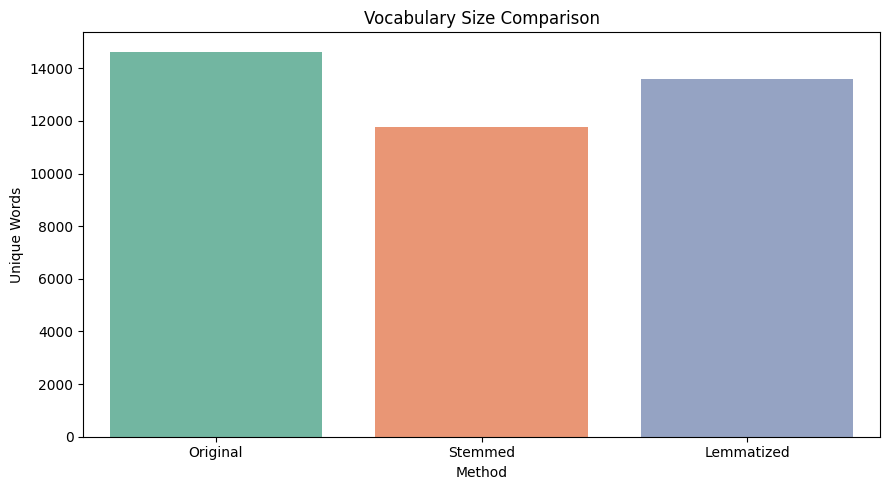

In [16]:
# Apply stemming and lemmatization to the same vocabulary

def stem_words(tokens):
    return [stemmer.stem(word) for word in tokens]


def lemmatize_words(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]


df['stemmed_tokens'] = df['tokens_without_stopwords'].apply(
    stem_words
)

df['lemmatized_tokens'] = df['tokens_without_stopwords'].apply(
    lemmatize_words
)

# Compare actual tweets
print("STEMMING VS LEMMATIZATION")

display(df[
    ['tokens_without_stopwords',
     'stemmed_tokens',
     'lemmatized_tokens']
].head(10))


# Compare the same actual vocabulary
word_counts = Counter(
    word
    for tokens in df['tokens_without_stopwords']
    for word in tokens
)

top_words = [
    word for word, count in word_counts.most_common(30)
]

word_comparison = pd.DataFrame({
    'Original Word': top_words,
    'Stemmed': [stemmer.stem(w) for w in top_words],
    'Lemmatized': [lemmatizer.lemmatize(w) for w in top_words]
})

print("Word Comparison:")
display(word_comparison)


# Calculate vocabulary sizes
original_vocab = set(
    word for text in df['cleaned_text']
    for word in text.split()
)

stemmed_vocab = set(
    word for tokens in df['stemmed_tokens']
    for word in tokens
)

lemmatized_vocab = set(
    word for tokens in df['lemmatized_tokens']
    for word in tokens
)

vocab_comparison = pd.DataFrame({
    'Method': ['Original', 'Stemmed', 'Lemmatized'],
    'Vocabulary Size': [
        len(original_vocab),
        len(stemmed_vocab),
        len(lemmatized_vocab)
    ]
})

display(vocab_comparison)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=vocab_comparison,
    x='Method',
    y='Vocabulary Size',
    hue='Method',
    palette='Set2',
    legend=False
)

plt.title('Vocabulary Size Comparison')
plt.ylabel('Unique Words')
plt.tight_layout()
plt.show()

## 4.

FINAL CLEANING MEASUREMENTS


,Vocabulary Size,Total Words,Average Tweet Length,Empty Tweets,Vocabulary Loss (%)
Original,16891.0,294127.0,20.09,0.0,0.00
Cleaned,14635.0,238870.0,16.32,0.0,13.36
Stopword Removed,14506.0,138837.0,9.48,16.0,14.12
Stemming,11782.0,138837.0,9.48,16.0,30.25
Lemmatization,13585.0,138837.0,9.48,16.0,19.57


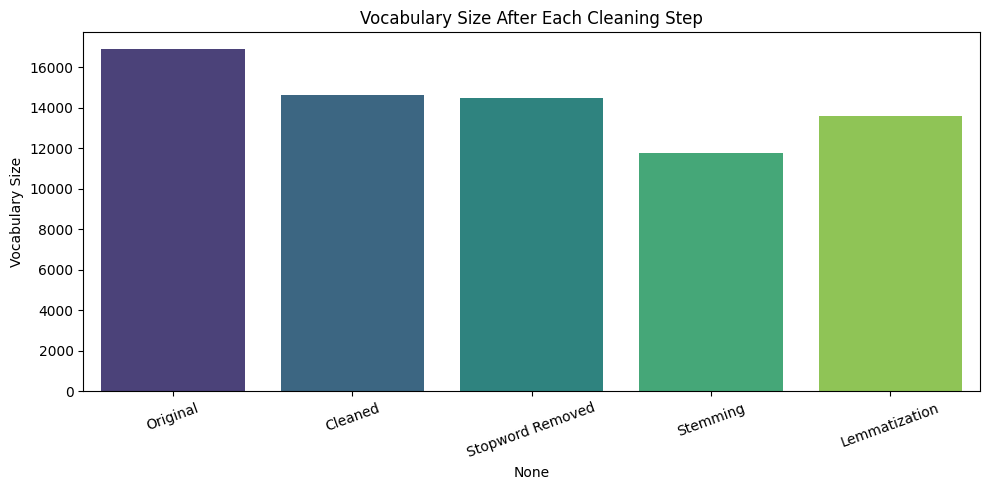

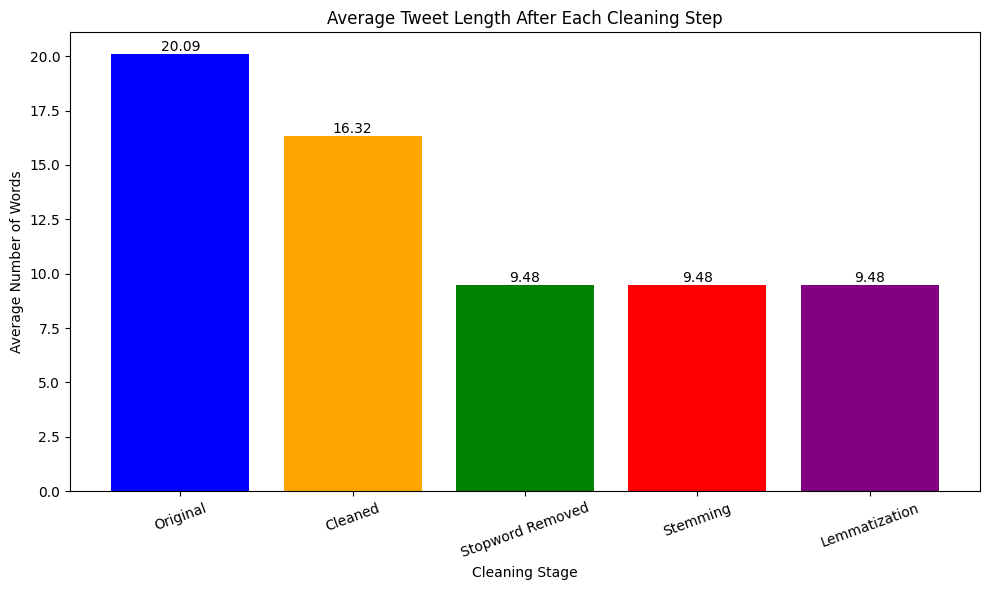

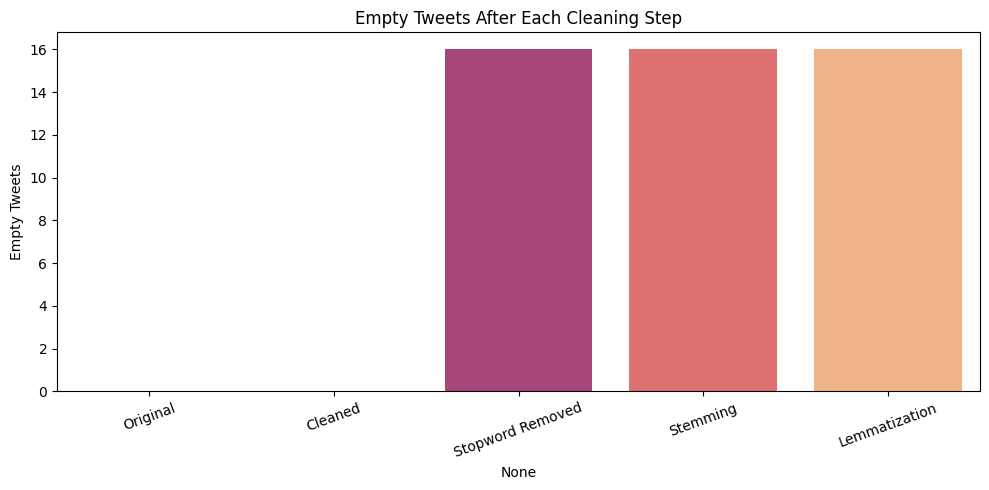


FINAL SUMMARY
Total Tweets: 14640
Original Vocabulary: 16891.0
Final Lemmatized Vocabulary: 13585
Original Average Tweet Length: 20.09
Final Average Tweet Length: 9.48
Empty Tweets After Cleaning: 16.0


In [19]:
# Create preprocessing stages

df['original_tokens'] = df['text'].apply(
    lambda x: tokenizer.tokenize(str(x).lower())
)

df['cleaned_tokens'] = df['cleaned_text'].apply(
    lambda x: x.split()
)

# Calculate measurements for each stage
def calculate_metrics(tokens_column):

    all_words = [
        word
        for tokens in df[tokens_column]
        for word in tokens
    ]

    vocabulary_size = len(set(all_words))
    total_words = len(all_words)

    average_length = np.mean([
        len(tokens)
        for tokens in df[tokens_column]
    ])

    empty_tweets = sum(
        len(tokens) == 0
        for tokens in df[tokens_column]
    )

    return {
        'Vocabulary Size': vocabulary_size,
        'Total Words': total_words,
        'Average Tweet Length': round(average_length, 2),
        'Empty Tweets': empty_tweets
    }


# Compare all cleaning stages
results = pd.DataFrame({
    'Original': calculate_metrics('original_tokens'),
    'Cleaned': calculate_metrics('cleaned_tokens'),
    'Stopword Removed': calculate_metrics('tokens_without_stopwords'),
    'Stemming': calculate_metrics('stemmed_tokens'),
    'Lemmatization': calculate_metrics('lemmatized_tokens')
}).T

# Calculate vocabulary loss
original_vocab_size = results.iloc[0]['Vocabulary Size']

results['Vocabulary Loss (%)'] = (
    (original_vocab_size - results['Vocabulary Size'])
    / original_vocab_size
) * 100

print("FINAL CLEANING MEASUREMENTS")
display(results.round(2))


# Plot 1: Vocabulary size
plt.figure(figsize=(10, 5))
sns.barplot(x=results.index, y=results['Vocabulary Size'],
            hue=results.index, palette='viridis', legend=False)
plt.title('Vocabulary Size After Each Cleaning Step')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Plot 2: Average tweet length
plt.figure(figsize=(10, 5))
sns.barplot(x=results.index, y=results['Average Tweet Length'],
            hue=results.index, palette='Set2', legend=False)
plt.title('Average Tweet Length After Each Cleaning Step')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Plot 3: Empty tweets
plt.figure(figsize=(10, 5))
sns.barplot(x=results.index, y=results['Empty Tweets'],
            hue=results.index, palette='magma', legend=False)
plt.title('Empty Tweets After Each Cleaning Step')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Final summary
print("\nFINAL SUMMARY")
print("Total Tweets:", len(df))
print("Original Vocabulary:", original_vocab_size)
print("Final Lemmatized Vocabulary:", len(lemmatized_vocab))
print("Original Average Tweet Length:",
      results.iloc[0]['Average Tweet Length'])
print("Final Average Tweet Length:",
      results.iloc[-1]['Average Tweet Length'])
print("Empty Tweets After Cleaning:",
      results.iloc[-1]['Empty Tweets'])

# Part B

## 1.

TOP 20 WORDS IN RAW DATA
[('to', 8648), ('the', 6060), ('i', 5452), ('a', 4501), ('you', 4136), ('for', 4001), ('flight', 3898), ('on', 3782), ('and', 3730), ('my', 3283), ('is', 2830), ('in', 2542), ('of', 2119), ('me', 1918), ('it', 1906), ('your', 1741), ('have', 1643), ('was', 1606), ('not', 1577), ('with', 1523)]


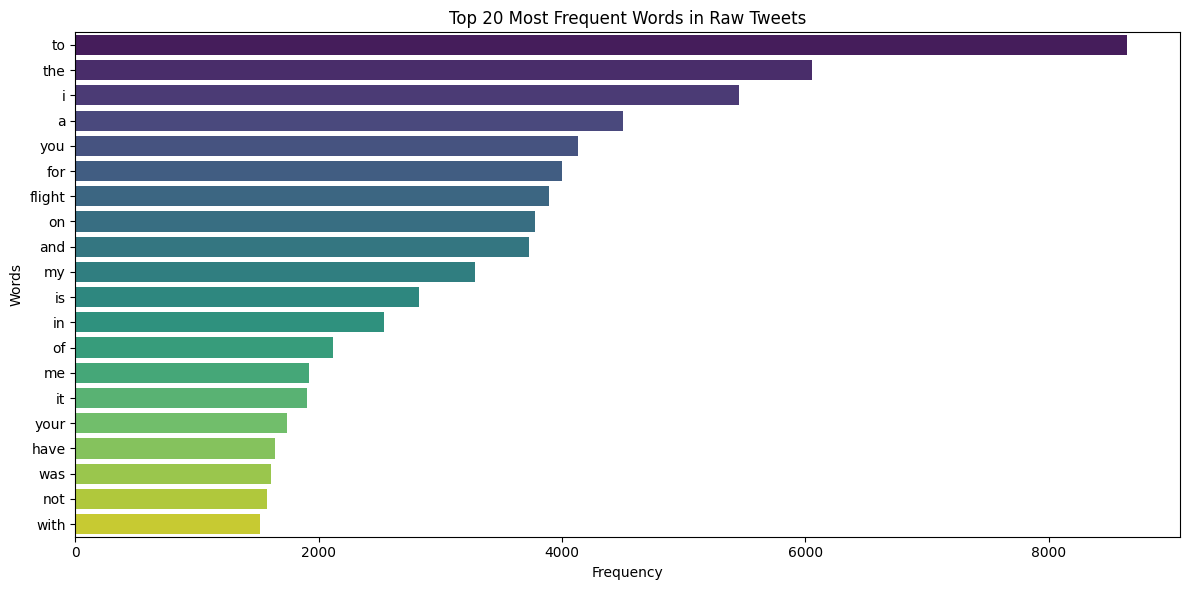


TOP 20 WORDS AFTER REMOVING GENERIC WORDS AND AIRLINE NAMES
[('get', 1334), ('thanks', 1072), ('cancelled', 1056), ('service', 956), ('help', 855), ('time', 770), ('im', 764), ('customer', 746), ('us', 679), ('hours', 669), ('hold', 637), ('plane', 618), ('thank', 602), ('cant', 578), ('still', 570), ('please', 560), ('one', 558), ('need', 553), ('would', 548), ('delayed', 529)]


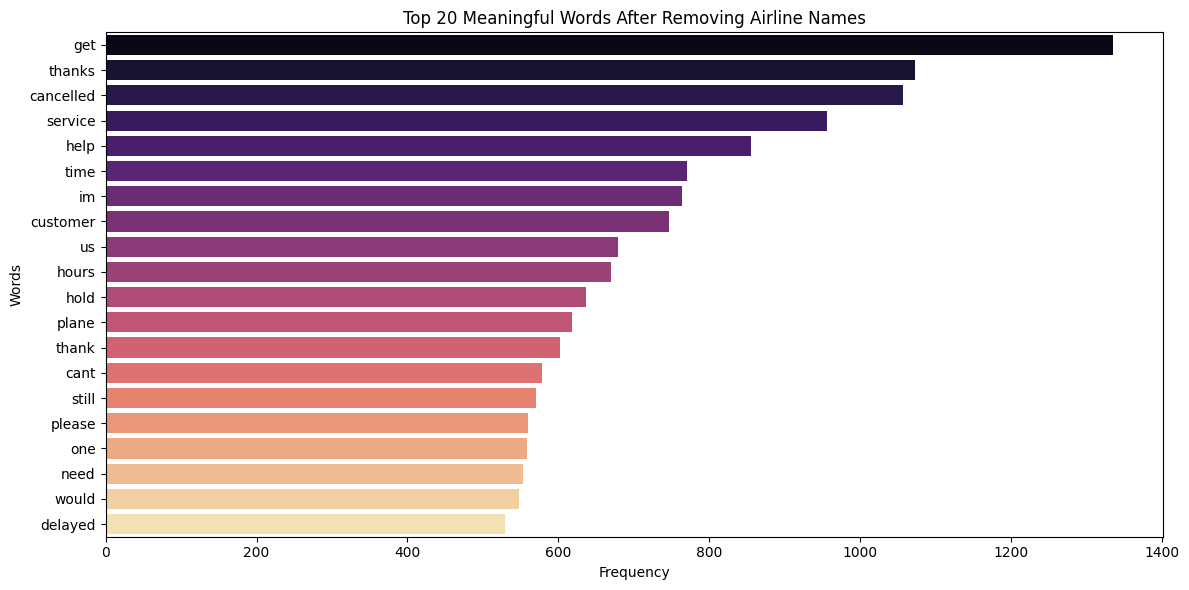

In [21]:
# Q5: Most Frequent Words in Airline Tweets

# Get all words from original tweets
raw_words = [
    word.lower()
    for tweet in df['text']
    for word in tokenizer.tokenize(tweet)
    if word.isalpha()
]

# Count raw word frequencies
raw_counts = Counter(raw_words)

print("TOP 20 WORDS IN RAW DATA")
print(raw_counts.most_common(20))

# Plot raw frequent words
raw_top = pd.DataFrame(
    raw_counts.most_common(20),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=raw_top,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='viridis',
    legend=False
)

plt.title("Top 20 Most Frequent Words in Raw Tweets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()


# Remove generic filler words and airline names
custom_stopwords = {
    'united', 'usairways', 'americanair', 'southwestair',
    'jetblue', 'virginamerica', 'delta',
    'flight', 'flights', 'airline', 'airlines',
    'amp', 'co', 'http', 'https', 'rt'
}

# Combine with existing stopwords
all_stopwords = stop_words.union(custom_stopwords)

# Get cleaned meaningful words
filtered_words = [
    word.lower()
    for tweet in df['cleaned_text']
    for word in tweet.split()
    if word.isalpha() and word.lower() not in all_stopwords
]

filtered_counts = Counter(filtered_words)

print("\nTOP 20 WORDS AFTER REMOVING GENERIC WORDS AND AIRLINE NAMES")
print(filtered_counts.most_common(20))

# Plot meaningful frequent words
filtered_top = pd.DataFrame(
    filtered_counts.most_common(20),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=filtered_top,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='magma',
    legend=False
)

plt.title("Top 20 Meaningful Words After Removing Airline Names")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

## 6.

Sentiment Categories:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
WORDS DISTINCTIVE TO NEGATIVE TWEETS


,Word,Positive TF-IDF,Negative TF-IDF,Difference
500,cancelled,0.003236,0.020690,0.017455
1383,hours,0.000615,0.016177,0.015562
1355,hold,0.000822,0.016315,0.015493
806,delayed,0.001645,0.013370,0.011725
1233,get,0.009917,0.021156,0.011239
1145,flightled,0.001287,0.012263,0.010976
1382,hour,0.001507,0.012347,0.010840
490,call,0.001896,0.012011,0.010114
2533,still,0.003984,0.012931,0.008946
900,dont,0.002425,0.011041,0.008617


WORDS DISTINCTIVE TO POSITIVE TWEETS


,Word,Positive TF-IDF,Negative TF-IDF,Difference
2638,thanks,0.090779,0.006995,-0.083783
2635,thank,0.082408,0.002090,-0.080318
1268,great,0.033395,0.002412,-0.030983
1641,love,0.023079,0.001908,-0.021172
351,awesome,0.018024,0.000584,-0.017440
1780,much,0.018409,0.002964,-0.015445
400,best,0.016917,0.002040,-0.014876
1259,good,0.015990,0.004264,-0.011725
251,amazing,0.012111,0.000531,-0.011580
290,appreciate,0.011167,0.001469,-0.009697


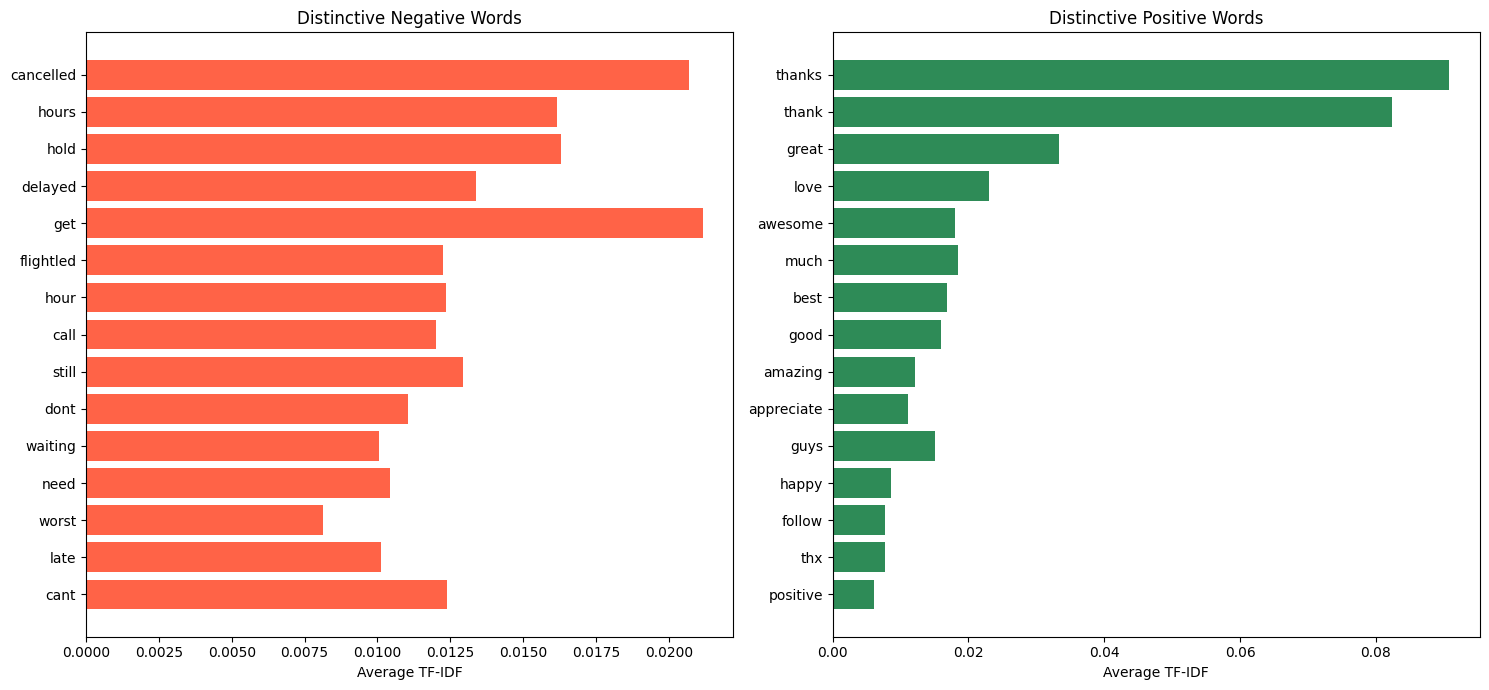

In [22]:
# Q6: Compare Positive and Negative Tweets

from sklearn.feature_extraction.text import TfidfVectorizer

# Check sentiment categories
print("Sentiment Categories:")
print(df['airline_sentiment'].value_counts())

# Separate positive and negative tweets
positive_tweets = df[
    df['airline_sentiment'] == 'positive'
]['cleaned_text']

negative_tweets = df[
    df['airline_sentiment'] == 'negative'
]['cleaned_text']

# Prepare documents
documents = [
    ' '.join(
        word for word in tweet.split()
        if word not in all_stopwords
    )
    for tweet in positive_tweets
] + [
    ' '.join(
        word for word in tweet.split()
        if word not in all_stopwords
    )
    for tweet in negative_tweets
]

# Calculate TF-IDF
vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 1)
)

tfidf_matrix = vectorizer.fit_transform(documents)

terms = vectorizer.get_feature_names_out()

# Separate positive and negative TF-IDF averages
positive_size = len(positive_tweets)

positive_scores = np.asarray(
    tfidf_matrix[:positive_size].mean(axis=0)
).flatten()

negative_scores = np.asarray(
    tfidf_matrix[positive_size:].mean(axis=0)
).flatten()

# Calculate difference
difference = negative_scores - positive_scores

comparison = pd.DataFrame({
    'Word': terms,
    'Positive TF-IDF': positive_scores,
    'Negative TF-IDF': negative_scores,
    'Difference': difference
})

# Most distinctive negative words
negative_distinctive = comparison.sort_values(
    'Difference',
    ascending=False
).head(15)

# Most distinctive positive words
positive_distinctive = comparison.sort_values(
    'Difference',
    ascending=True
).head(15)

print("WORDS DISTINCTIVE TO NEGATIVE TWEETS")
display(negative_distinctive)

print("WORDS DISTINCTIVE TO POSITIVE TWEETS")
display(positive_distinctive)

# Butterfly chart
negative_words = negative_distinctive['Word'].iloc[::-1]
negative_values = negative_distinctive['Negative TF-IDF'].iloc[::-1]

positive_words = positive_distinctive['Word'].iloc[::-1]
positive_values = positive_distinctive['Positive TF-IDF'].iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(
    negative_words,
    negative_values,
    color='tomato'
)

axes[0].set_title("Distinctive Negative Words")
axes[0].set_xlabel("Average TF-IDF")

axes[1].barh(
    positive_words,
    positive_values,
    color='seagreen'
)

axes[1].set_title("Distinctive Positive Words")
axes[1].set_xlabel("Average TF-IDF")

plt.tight_layout()
plt.show()

## 7.

TOP 20 BIGRAMS IN NEGATIVE TWEETS


,Bigram,Frequency
578,customer service,444
413,cancelled flightled,438
409,cancelled flighted,197
1483,late flightr,142
441,cant get,106
376,call back,97
356,booking problems,97
976,gate agent,62
1424,ive hold,60
2125,please help,60


TOP 20 TRIGRAMS IN NEGATIVE TWEETS


,Trigram,Frequency
2929,worst customer service,42
2453,reflight booking problems,38
1938,hours late flightr,32
2390,poor customer service,21
2078,late flightr still,19
2658,terrible customer service,19
1102,call customer service,16
1014,back late flightr,15
1095,call back late,14
1800,got cancelled flightled,14


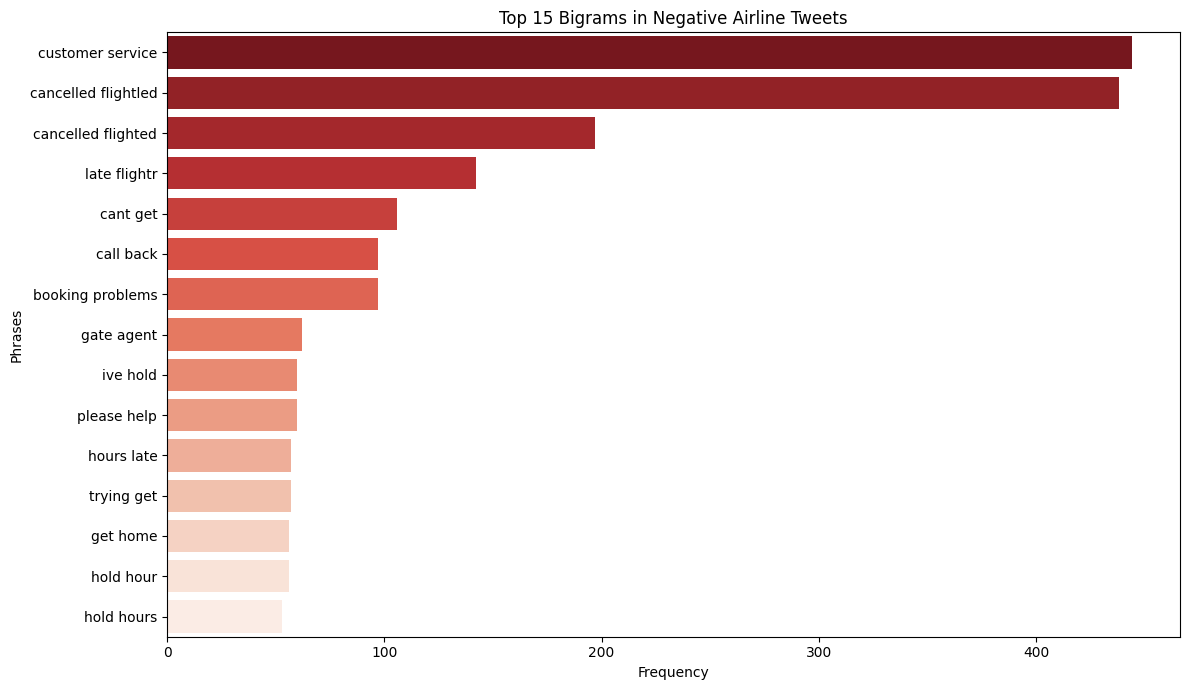

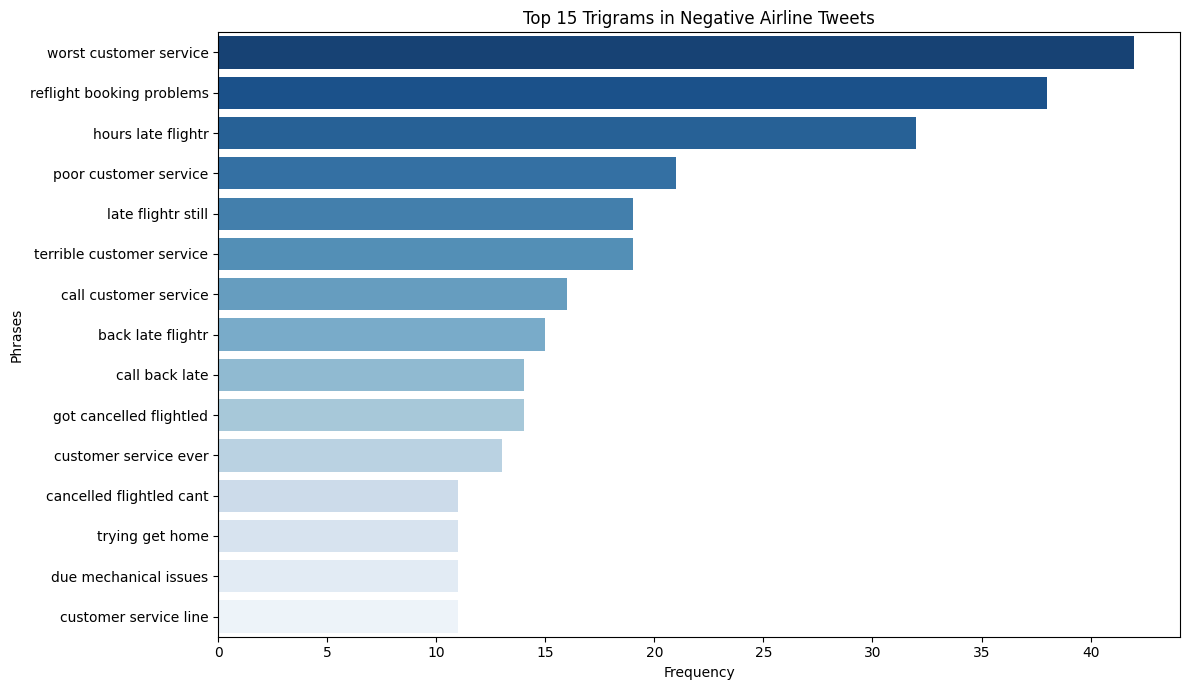

In [23]:
# Q7: Bigram and Trigram Analysis

from sklearn.feature_extraction.text import CountVectorizer

# Get negative tweets
negative_texts = df[
    df['airline_sentiment'] == 'negative'
]['cleaned_text']

# Prepare text
negative_documents = [
    ' '.join(
        word for word in tweet.split()
        if word not in all_stopwords
    )
    for tweet in negative_texts
]

# Bigram analysis
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=3000
)

bigram_matrix = bigram_vectorizer.fit_transform(
    negative_documents
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).flatten()

bigrams = bigram_vectorizer.get_feature_names_out()

bigram_results = pd.DataFrame({
    'Bigram': bigrams,
    'Frequency': bigram_counts
}).sort_values(
    'Frequency',
    ascending=False
)

print("TOP 20 BIGRAMS IN NEGATIVE TWEETS")
display(bigram_results.head(20))


# Trigram analysis
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    max_features=3000
)

trigram_matrix = trigram_vectorizer.fit_transform(
    negative_documents
)

trigram_counts = np.asarray(
    trigram_matrix.sum(axis=0)
).flatten()

trigrams = trigram_vectorizer.get_feature_names_out()

trigram_results = pd.DataFrame({
    'Trigram': trigrams,
    'Frequency': trigram_counts
}).sort_values(
    'Frequency',
    ascending=False
)

print("TOP 20 TRIGRAMS IN NEGATIVE TWEETS")
display(trigram_results.head(20))


# Plot top bigrams
top_bigrams = bigram_results.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_bigrams,
    x='Frequency',
    y='Bigram',
    hue='Bigram',
    palette='Reds_r',
    legend=False
)

plt.title("Top 15 Bigrams in Negative Airline Tweets")
plt.xlabel("Frequency")
plt.ylabel("Phrases")
plt.tight_layout()
plt.show()


# Plot top trigrams
top_trigrams = trigram_results.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_trigrams,
    x='Frequency',
    y='Trigram',
    hue='Trigram',
    palette='Blues_r',
    legend=False
)

plt.title("Top 15 Trigrams in Negative Airline Tweets")
plt.xlabel("Frequency")
plt.ylabel("Phrases")
plt.tight_layout()
plt.show()

In [24]:
# Find negation phrases in actual negative tweets

negation_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    vocabulary=None,
    max_features=3000,
    token_pattern=r'(?u)\b\w+\b'
)

# Keep negation words in this analysis
negative_documents_with_negation = [
    tweet for tweet in negative_texts
]

negation_matrix = negation_vectorizer.fit_transform(
    negative_documents_with_negation
)

negation_counts = np.asarray(
    negation_matrix.sum(axis=0)
).flatten()

negation_bigrams = negation_vectorizer.get_feature_names_out()

negation_results = pd.DataFrame({
    'Phrase': negation_bigrams,
    'Frequency': negation_counts
}).sort_values(
    'Frequency',
    ascending=False
)

# Display phrases containing negation
negation_results = negation_results[
    negation_results['Phrase'].str.contains(
        r'\b(not|no|nor|never)\b',
        regex=True
    )
]

print("NEGATION PHRASES IN NEGATIVE TWEETS")
display(negation_results.head(20))

NEGATION PHRASES IN NEGATIVE TWEETS


/tmp/ipykernel_42381/3895371750.py:35: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  negation_results['Phrase'].str.contains(


,Phrase,Frequency
1743,no one,119
1369,is not,102
2860,with no,92
283,and no,91
1433,its not,65
2178,still no,62
1757,not a,51
284,and not,49
1281,im not,45
1066,have no,45


## 8.

TOP 20 NEGATIVE WORDS
[('get', 982), ('cancelled', 920), ('service', 742), ('hours', 644), ('help', 610), ('hold', 607), ('customer', 604), ('time', 584), ('im', 547), ('plane', 516), ('delayed', 493), ('cant', 485), ('us', 483), ('still', 479), ('call', 448), ('flightled', 442), ('hour', 435), ('one', 433), ('dont', 412), ('bag', 408)]


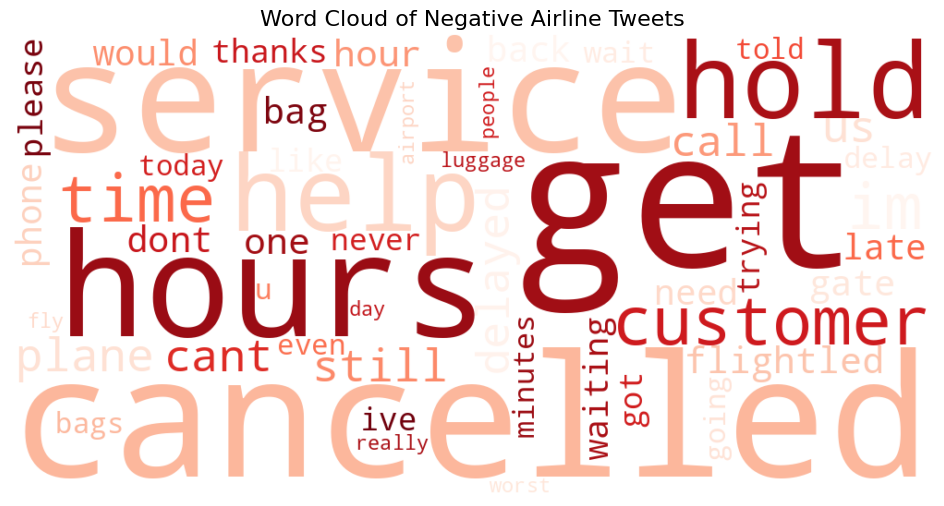

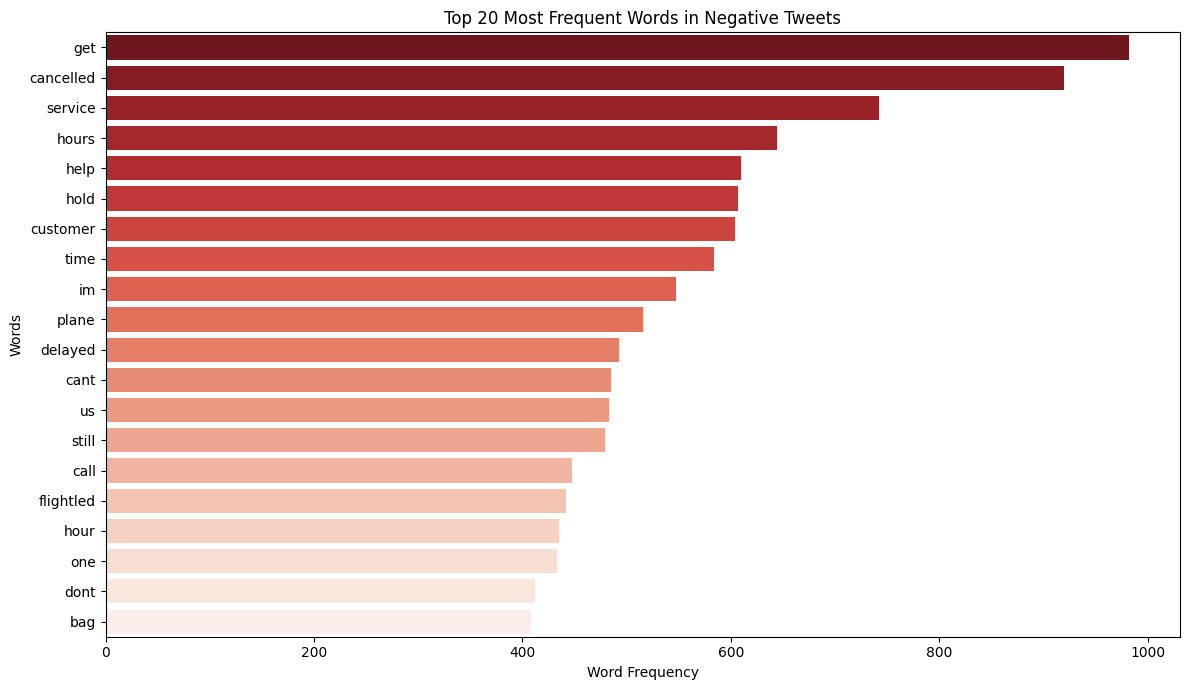

In [25]:
# Q8: Word Cloud vs Bar Chart

from wordcloud import WordCloud

# Get negative tweet words
negative_words = [
    word
    for tweet in negative_texts
    for word in tweet.split()
    if word.isalpha() and word not in all_stopwords
]

# Count negative words
negative_counts = Counter(negative_words)

print("TOP 20 NEGATIVE WORDS")
print(negative_counts.most_common(20))


# Generate word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Reds',
    max_words=50
).generate_from_frequencies(negative_counts)

plt.figure(figsize=(14, 6))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title(
    "Word Cloud of Negative Airline Tweets",
    fontsize=16
)

plt.show()


# Generate frequency bar chart
top_negative = pd.DataFrame(
    negative_counts.most_common(20),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_negative,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='Reds_r',
    legend=False
)

plt.title("Top 20 Most Frequent Words in Negative Tweets")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

plt.tight_layout()
plt.show()

# Part C

## 9.

In [26]:
!pip install vaderSentiment -q

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

analyzer = SentimentIntensityAnalyzer()

print("VADER Sentiment Analyzer Ready!")

VADER Sentiment Analyzer Ready!


,text,airline_sentiment,compound,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral,0.0000,neutral
1,@VirginAmerica plus you've added commercials t...,positive,0.0000,neutral
2,@VirginAmerica I didn't today... Must mean I n...,neutral,0.0000,neutral
3,@VirginAmerica it's really aggressive to blast...,negative,-0.2716,negative
4,@VirginAmerica and it's a really big bad thing...,negative,-0.5829,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative,-0.5945,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive,0.6908,positive
7,@VirginAmerica Really missed a prime opportuni...,neutral,0.0790,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,0.7525,positive
9,"@VirginAmerica it was amazing, and arrived an ...",positive,0.7717,positive


Overall VADER Accuracy: 48.99 %

Classification Report:
              precision    recall  f1-score   support

    positive       0.28      0.91      0.43      2363
     neutral       0.39      0.32      0.35      3099
    negative       0.90      0.44      0.59      9178

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640



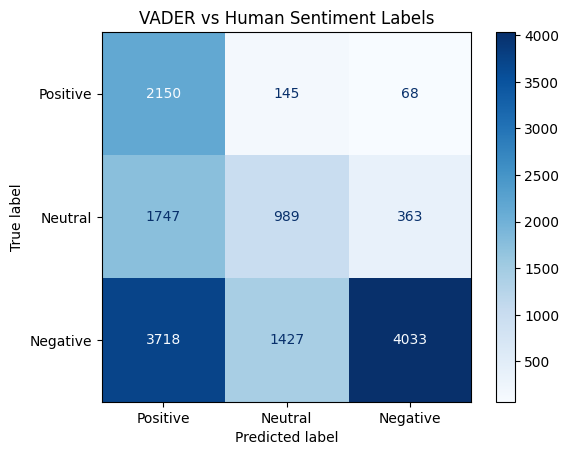


Recall by Sentiment Class:


,Sentiment,Recall
0,positive,0.909860
1,neutral,0.319135
2,negative,0.439420


Hardest class: neutral


In [28]:
# Q9: Sentiment Analysis Using VADER

# Remove rows with missing text or sentiment labels
sentiment_df = df.dropna(
    subset=['text', 'airline_sentiment']
).copy()

# Calculate VADER sentiment scores
sentiment_df['vader_scores'] = sentiment_df['text'].apply(
    lambda tweet: analyzer.polarity_scores(tweet)
)

# Extract compound scores
sentiment_df['compound'] = sentiment_df['vader_scores'].apply(
    lambda score: score['compound']
)

# Convert compound scores into sentiment classes
def predict_sentiment(score):

    if score >= 0.05:
        return 'positive'

    elif score <= -0.05:
        return 'negative'

    else:
        return 'neutral'


sentiment_df['vader_sentiment'] = sentiment_df['compound'].apply(
    predict_sentiment
)

# Display actual and predicted results
display(
    sentiment_df[
        ['text', 'airline_sentiment', 'compound', 'vader_sentiment']
    ].head(15)
)

# Calculate accuracy
human_labels = sentiment_df['airline_sentiment']
predicted_labels = sentiment_df['vader_sentiment']

accuracy = accuracy_score(
    human_labels,
    predicted_labels
)

print("Overall VADER Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        human_labels,
        predicted_labels,
        labels=['positive', 'neutral', 'negative'],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    human_labels,
    predicted_labels,
    labels=['positive', 'neutral', 'negative']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Positive', 'Neutral', 'Negative']
)

disp.plot(cmap='Blues', values_format='d')

plt.title("VADER vs Human Sentiment Labels")
plt.show()

# Identify hardest class using recall
report = classification_report(
    human_labels,
    predicted_labels,
    labels=['positive', 'neutral', 'negative'],
    output_dict=True,
    zero_division=0
)

class_recall = pd.DataFrame({
    'Sentiment': ['positive', 'neutral', 'negative'],
    'Recall': [
        report['positive']['recall'],
        report['neutral']['recall'],
        report['negative']['recall']
    ]
})

print("\nRecall by Sentiment Class:")
display(class_recall)

print(
    "Hardest class:",
    class_recall.loc[class_recall['Recall'].idxmin(), 'Sentiment']
)

## 10.

Total Disagreements: 7468

Disagreement Percentage: 51.01 %


,text,airline_sentiment,vader_sentiment,compound,cause
1,@VirginAmerica plus you've added commercials t...,positive,neutral,0.0000,Other / Context missing
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive,0.0790,Other / Context missing
10,@VirginAmerica did you know that suicide is th...,neutral,negative,-0.8555,Negation
16,@VirginAmerica So excited for my first cross c...,positive,negative,-0.5566,Negation
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive,0.5754,Negation
20,@VirginAmerica why are your first fares in May...,negative,neutral,0.0000,Other / Context missing
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative,-0.2960,Negation
24,@VirginAmerica you guys messed up my seating.....,negative,positive,0.6486,Other / Context missing
27,@VirginAmerica do you miss me? Don't worry we'...,neutral,positive,0.2037,Negation
28,@VirginAmerica amazing to me that we can't get...,negative,positive,0.5859,Negation



Disagreement Causes:


,cause,count
0,Other / Context missing,3878
1,Negation,3036
2,Airline-specific words,511
3,Mixed feelings,24
4,Sarcasm,19


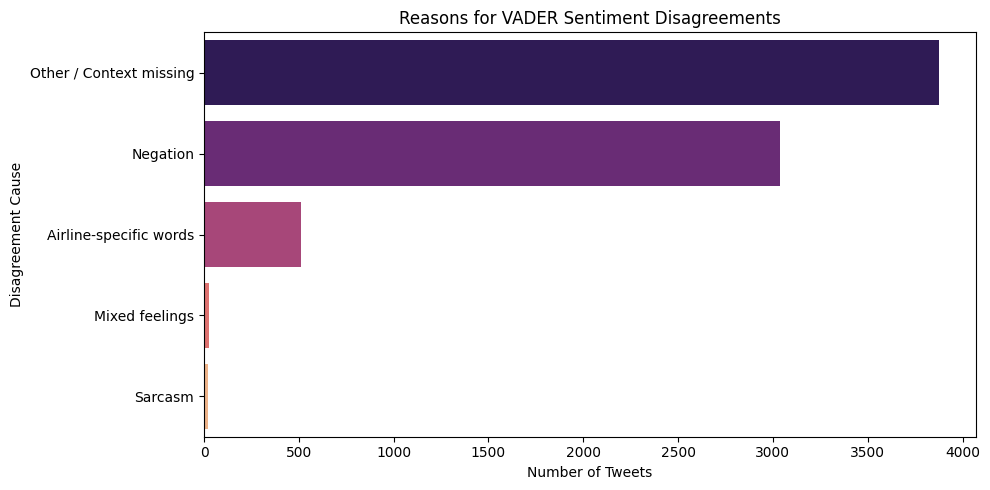


Largest Disagreement Cause: Other / Context missing
Number of Tweets: 3878


In [29]:
# Q10: Analyze Sentiment Disagreements

# Select tweets where VADER disagrees with human labels
disagreements = sentiment_df[
    sentiment_df['airline_sentiment'] !=
    sentiment_df['vader_sentiment']
].copy()

print("Total Disagreements:", len(disagreements))

print("\nDisagreement Percentage:",
      round(len(disagreements) / len(sentiment_df) * 100, 2), "%")


# Function to identify possible disagreement causes
def identify_cause(row):

    tweet = str(row['text']).lower()

    # Sarcasm indicators
    sarcasm_words = [
        'yeah right', 'great job', 'thanks a lot',
        'just perfect', 'wonderful'
    ]

    # Negation indicators
    negation_words = [
        'not', 'no', 'never', "isn't", "wasn't",
        "don't", "didn't", "can't", "couldn't"
    ]

    # Airline-specific operational words
    airline_words = [
        'delayed', 'delay', 'cancelled', 'canceled',
        'cancellation', 'lost luggage', 'baggage',
        'stranded', 'rerouted', 'rescheduled',
        'missed connection'
    ]

    # Mixed sentiment indicators
    positive_words = [
        'good', 'great', 'excellent', 'love',
        'happy', 'helpful', 'thanks'
    ]

    negative_words = [
        'bad', 'terrible', 'awful', 'worst',
        'angry', 'late', 'poor', 'hate'
    ]

    has_sarcasm = any(word in tweet for word in sarcasm_words)

    has_negation = any(word in tweet for word in negation_words)

    has_airline = any(word in tweet for word in airline_words)

    has_positive = any(word in tweet for word in positive_words)

    has_negative = any(word in tweet for word in negative_words)

    # Assign a primary possible cause
    if has_sarcasm:
        return 'Sarcasm'

    elif has_negation:
        return 'Negation'

    elif has_airline:
        return 'Airline-specific words'

    elif has_positive and has_negative:
        return 'Mixed feelings'

    else:
        return 'Other / Context missing'


# Apply cause classification
disagreements['cause'] = disagreements.apply(
    identify_cause,
    axis=1
)

# Display disagreement examples
display(
    disagreements[
        ['text', 'airline_sentiment', 'vader_sentiment',
         'compound', 'cause']
    ].head(25)
)


# Count disagreement causes
cause_counts = disagreements['cause'].value_counts()

print("\nDisagreement Causes:")
display(cause_counts.reset_index())


# Plot disagreement causes
plt.figure(figsize=(10, 5))

sns.barplot(
    x=cause_counts.values,
    y=cause_counts.index,
    hue=cause_counts.index,
    palette='magma',
    legend=False
)

plt.title("Reasons for VADER Sentiment Disagreements")
plt.xlabel("Number of Tweets")
plt.ylabel("Disagreement Cause")

plt.tight_layout()
plt.show()


# Identify largest cause
if len(cause_counts) > 0:

    print("\nLargest Disagreement Cause:", cause_counts.idxmax())

    print("Number of Tweets:", cause_counts.max())

else:
    print("No disagreements found.")

## 11.

In [30]:
# Q11: Test VADER on three original tweets

own_tweets = [
    {
        'Tweet': 'Great! Another 8 hour flight delay. Just wonderful!',
        'Expected Sentiment': 'Negative',
        'Failure Type': 'Sarcasm'
    },

    {
        'Tweet': 'The flight was not good and the service was not helpful.',
        'Expected Sentiment': 'Negative',
        'Failure Type': 'Negation'
    },

    {
        'Tweet': 'The cabin crew was amazing, but my luggage was lost and my flight was cancelled.',
        'Expected Sentiment': 'Negative',
        'Failure Type': 'Mixed Feelings'
    }
]

# Convert to DataFrame
own_df = pd.DataFrame(own_tweets)

# Apply VADER
own_df['VADER Score'] = own_df['Tweet'].apply(
    lambda tweet: analyzer.polarity_scores(tweet)['compound']
)

own_df['VADER Prediction'] = own_df['VADER Score'].apply(
    predict_sentiment
)

print("ORIGINAL TEST TWEETS AND VADER RESULTS")

display(own_df)

# Compare expected and predicted sentiment
for _, row in own_df.iterrows():

    print("\nTweet:", row['Tweet'])

    print("Failure Type:", row['Failure Type'])

    print("Expected:", row['Expected Sentiment'])

    print("VADER Prediction:", row['VADER Prediction'])

    print("VADER Score:", row['VADER Score'])

    if row['Expected Sentiment'] != row['VADER Prediction']:
        print("Result: VADER disagrees with expected sentiment.")
    else:
        print("Result: VADER agrees with expected sentiment.")

ORIGINAL TEST TWEETS AND VADER RESULTS


,Tweet,Expected Sentiment,Failure Type,VADER Score,VADER Prediction
0,Great! Another 8 hour flight delay. Just wonde...,Negative,Sarcasm,0.7955,positive
1,The flight was not good and the service was no...,Negative,Negation,-0.5773,negative
2,"The cabin crew was amazing, but my luggage was...",Negative,Mixed Feelings,-0.4678,negative



Tweet: Great! Another 8 hour flight delay. Just wonderful!
Failure Type: Sarcasm
Expected: Negative
VADER Prediction: positive
VADER Score: 0.7955
Result: VADER disagrees with expected sentiment.

Tweet: The flight was not good and the service was not helpful.
Failure Type: Negation
Expected: Negative
VADER Prediction: negative
VADER Score: -0.5773
Result: VADER disagrees with expected sentiment.

Tweet: The cabin crew was amazing, but my luggage was lost and my flight was cancelled.
Failure Type: Mixed Feelings
Expected: Negative
VADER Prediction: negative
VADER Score: -0.4678
Result: VADER disagrees with expected sentiment.


## 12.

Available Dataset Columns:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'cleaned_text', 'tokens_without_stopwords', 'stemmed_tokens', 'lemmatized_tokens', 'original_tokens', 'cleaned_tokens']

Confidence Column Found: airline_sentiment_confidence

All Labels Accuracy: 48.99 %
High Confidence Tweets: 10459
High Confidence Accuracy: 53.13 %

High Confidence Classification Report:
              precision    recall  f1-score   support

    negative       0.95      0.48      0.64      7392
     neutral       0.34      0.37      0.35      1550
    positive       0.29      0.94      0.44      1517

    accuracy                           0.53     10459
   macro avg       0.52      0.60      0.48     10459
weighted avg       0.76      0.53      0.57     10459



,Dataset,Accuracy (%)
0,All Labels,48.989071
1,High Confidence Labels,53.131275


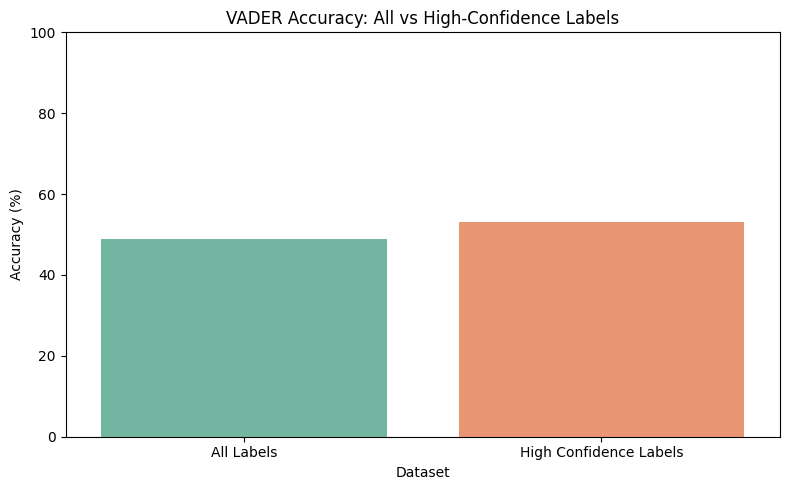

In [31]:
# Q12: Human Label Confidence Analysis

# Search for possible confidence columns
possible_columns = [
    'label_confidence',
    'confidence',
    'sentiment_confidence',
    'airline_sentiment_confidence',
    'annotation_confidence'
]

confidence_column = next(
    (
        col for col in possible_columns
        if col in df.columns
    ),
    None
)

print("Available Dataset Columns:")
print(df.columns.tolist())


if confidence_column is not None:

    print("\nConfidence Column Found:", confidence_column)

    # Create confidence dataset
    confidence_df = df.dropna(
        subset=['text', 'airline_sentiment', confidence_column]
    ).copy()

    # Apply VADER
    confidence_df['compound'] = confidence_df['text'].apply(
        lambda tweet: analyzer.polarity_scores(tweet)['compound']
    )

    confidence_df['vader_sentiment'] = confidence_df['compound'].apply(
        predict_sentiment
    )

    # Accuracy using all available confidence-labelled tweets
    all_accuracy = accuracy_score(
        confidence_df['airline_sentiment'],
        confidence_df['vader_sentiment']
    )

    # Keep only high-confidence labels
    # For confidence values on a 0–1 scale
    if confidence_df[confidence_column].max() <= 1:

        high_confidence = confidence_df[
            confidence_df[confidence_column] >= 0.80
        ]

    # For confidence values on a 0–100 scale
    else:

        high_confidence = confidence_df[
            confidence_df[confidence_column] >= 80
        ]

    print("\nAll Labels Accuracy:",
          round(all_accuracy * 100, 2), "%")

    print("High Confidence Tweets:",
          len(high_confidence))

    if len(high_confidence) > 0:

        high_accuracy = accuracy_score(
            high_confidence['airline_sentiment'],
            high_confidence['vader_sentiment']
        )

        print("High Confidence Accuracy:",
              round(high_accuracy * 100, 2), "%")

        print("\nHigh Confidence Classification Report:")

        print(
            classification_report(
                high_confidence['airline_sentiment'],
                high_confidence['vader_sentiment'],
                zero_division=0
            )
        )

        # Compare accuracies
        confidence_comparison = pd.DataFrame({
            'Dataset': [
                'All Labels',
                'High Confidence Labels'
            ],
            'Accuracy (%)': [
                all_accuracy * 100,
                high_accuracy * 100
            ]
        })

        display(confidence_comparison)

        plt.figure(figsize=(8, 5))

        sns.barplot(
            data=confidence_comparison,
            x='Dataset',
            y='Accuracy (%)',
            hue='Dataset',
            palette='Set2',
            legend=False
        )

        plt.title('VADER Accuracy: All vs High-Confidence Labels')
        plt.ylabel('Accuracy (%)')
        plt.ylim(0, 100)
        plt.tight_layout()
        plt.show()

    else:

        print("No tweets meet the high-confidence threshold.")

else:

    print("\nNo label-confidence column was found in the dataset.")

    print("The dataset does not provide confidence information.")

    print("Therefore, high-confidence filtering cannot be performed.")

# Part D

## 13.

Available columns: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone', 'cleaned_text', 'tokens_without_stopwords', 'stemmed_tokens', 'lemmatized_tokens', 'original_tokens', 'cleaned_tokens']
Complaint Counts by Airline:


Complaint Type,Customer Service,Operations,Other
airline,,,
American,985,743,232
Delta,303,452,200
Southwest,490,508,188
US Airways,1056,911,296
United,993,1213,427
Virgin America,93,63,25


Complaint Percentages by Airline:


Complaint Type,Customer Service,Operations,Other
airline,,,
American,50.26,37.91,11.84
Delta,31.73,47.33,20.94
Southwest,41.32,42.83,15.85
US Airways,46.66,40.26,13.08
United,37.71,46.07,16.22
Virgin America,51.38,34.81,13.81


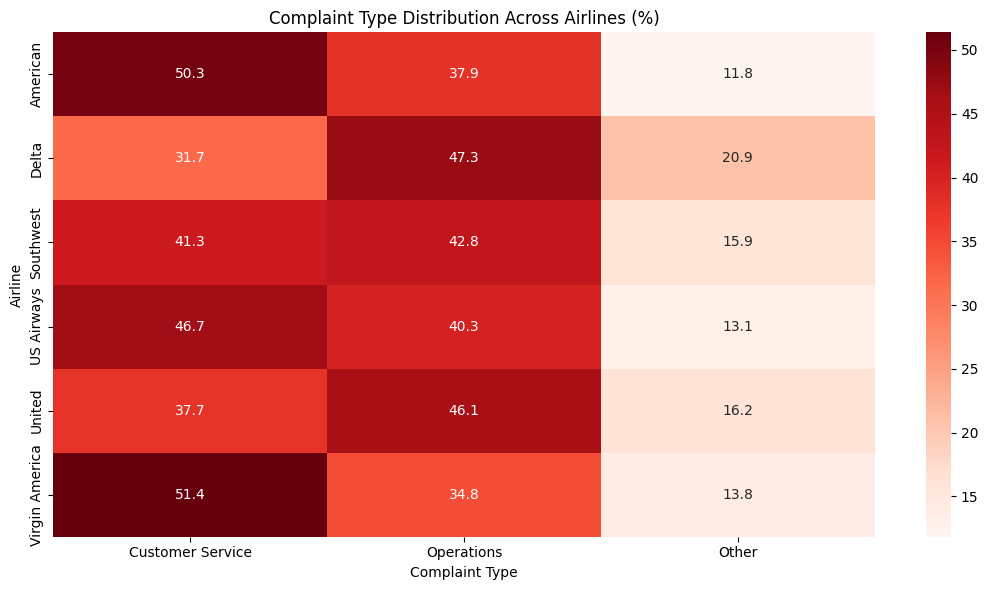

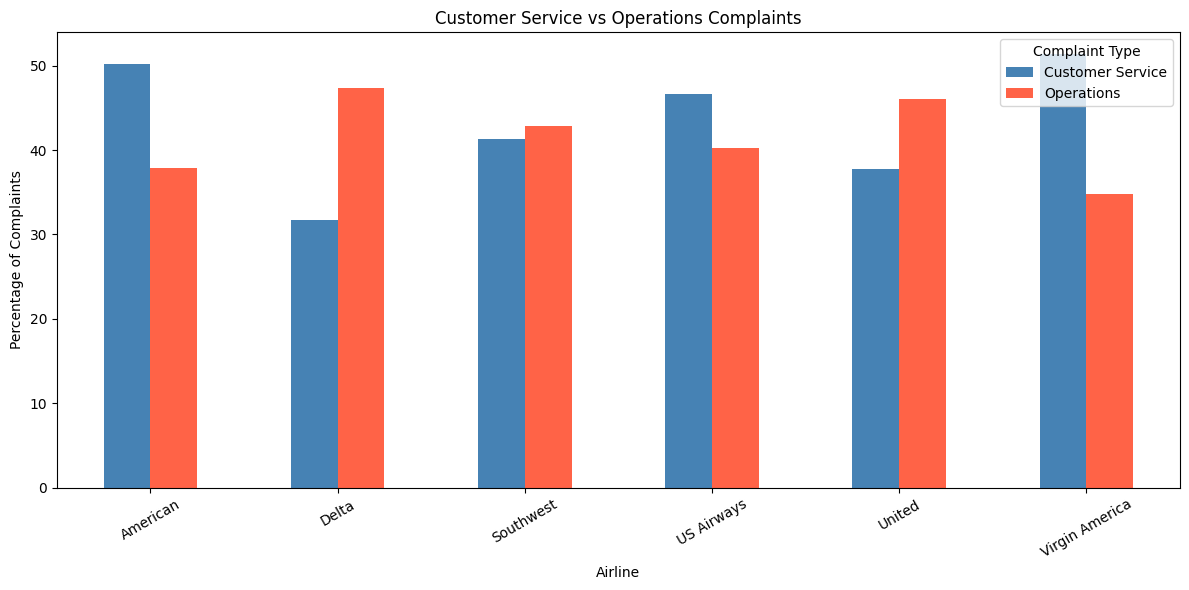


Airline with highest customer service complaint share:
Virgin America

Airline with highest operations complaint share:
Delta


In [32]:
# Q13: Airline Comparison and Complaint Analysis

# Check required columns
print("Available columns:", df.columns.tolist())

required = ['airline', 'airline_sentiment']

if not all(col in df.columns for col in required):
    raise ValueError("Airline or sentiment column is missing.")

# Select negative tweets
negative_df = df[
    df['airline_sentiment'].str.lower() == 'negative'
].copy()

# Check if complaint reason exists
if 'negativereason' in df.columns:

    # Remove missing complaint reasons
    complaint_df = negative_df.dropna(
        subset=['negativereason']
    ).copy()

    # Group complaint reasons into broader categories
    def complaint_type(reason):

        reason = str(reason).lower()

        if any(word in reason for word in [
            'customer service',
            'flight attendant',
            'booking',
            'long line'
        ]):
            return 'Customer Service'

        elif any(word in reason for word in [
            'late flight',
            'cancellation',
            'cancelled',
            'cancel',
            'lost luggage',
            'damaged luggage',
            'flight',
            'baggage'
        ]):
            return 'Operations'

        else:
            return 'Other'

    complaint_df['Complaint Type'] = (
        complaint_df['negativereason'].apply(complaint_type)
    )

    # Count complaints by airline and category
    complaint_counts = pd.crosstab(
        complaint_df['airline'],
        complaint_df['Complaint Type']
    )

    print("Complaint Counts by Airline:")
    display(complaint_counts)

    # Calculate percentage within each airline
    complaint_percentages = complaint_counts.div(
        complaint_counts.sum(axis=1),
        axis=0
    ) * 100

    print("Complaint Percentages by Airline:")
    display(complaint_percentages.round(2))

    # Heatmap
    plt.figure(figsize=(11, 6))

    sns.heatmap(
        complaint_percentages,
        annot=True,
        fmt='.1f',
        cmap='Reds'
    )

    plt.title('Complaint Type Distribution Across Airlines (%)')
    plt.xlabel('Complaint Type')
    plt.ylabel('Airline')
    plt.tight_layout()
    plt.show()

    # Compare customer service and operations
    if {'Customer Service', 'Operations'}.issubset(
        complaint_percentages.columns
    ):

        comparison = complaint_percentages[
            ['Customer Service', 'Operations']
        ]

        comparison.plot(
            kind='bar',
            figsize=(12, 6),
            color=['steelblue', 'tomato']
        )

        plt.title('Customer Service vs Operations Complaints')
        plt.ylabel('Percentage of Complaints')
        plt.xlabel('Airline')
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

        print("\nAirline with highest customer service complaint share:")
        print(comparison['Customer Service'].idxmax())

        print("\nAirline with highest operations complaint share:")
        print(comparison['Operations'].idxmax())

else:
    print("No negativereason column found in dataset.")

## 14.

Airline Sentiment Comparison:


airline_sentiment,negative,neutral,positive,Total Tweets,Negative Share (%)
airline,,,,,
American,1960,463,336,2759,71.04
Delta,955,723,544,2222,42.98
Southwest,1186,664,570,2420,49.01
US Airways,2263,381,269,2913,77.69
United,2633,697,492,3822,68.89
Virgin America,181,171,152,504,35.91


airline_sentiment,negative,Total Tweets,Negative Share (%),Negative Count Rank,Negative Share Rank
airline,,,,,
US Airways,2263,2913,77.69,2.0,1.0
American,1960,2759,71.04,3.0,2.0
United,2633,3822,68.89,1.0,3.0
Southwest,1186,2420,49.01,4.0,4.0
Delta,955,2222,42.98,5.0,5.0
Virgin America,181,504,35.91,6.0,6.0


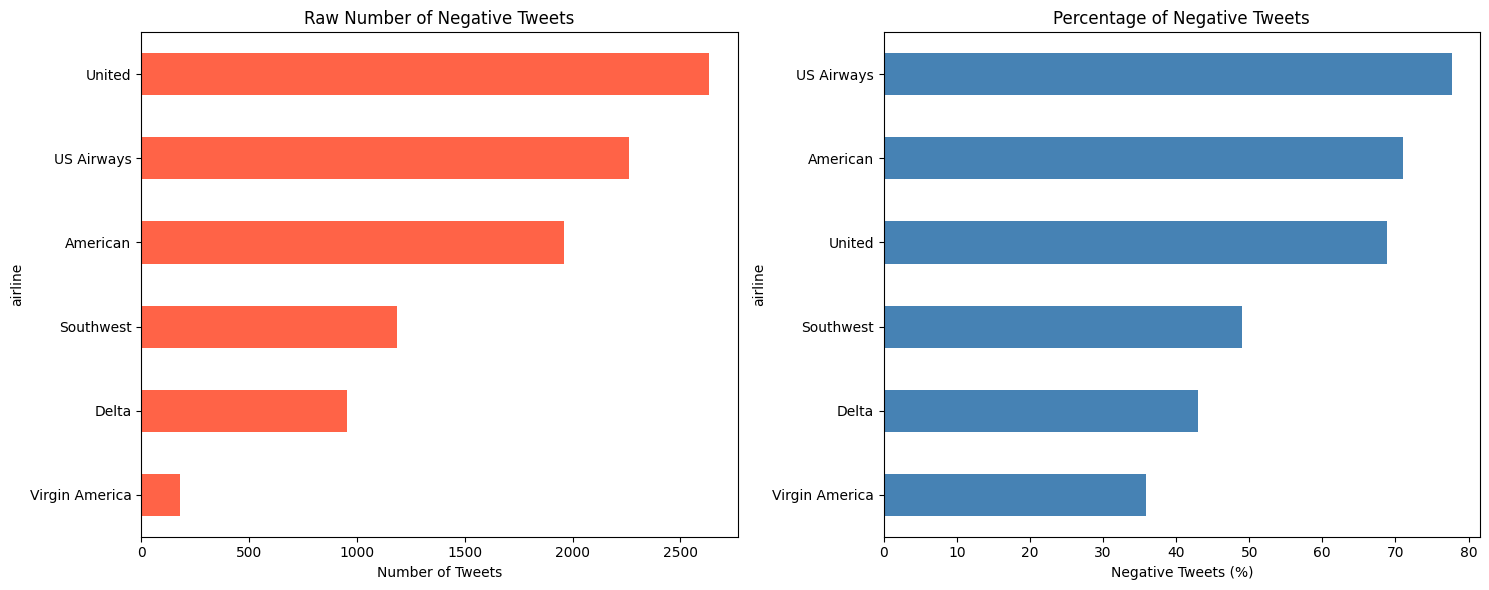


Airline with the biggest difference between rankings:


airline_sentiment,negative,Total Tweets,Negative Share (%),Negative Count Rank,Negative Share Rank
airline,,,,,
United,2633,3822,68.89,1.0,3.0


In [33]:
# Q14: Raw Counts vs Sentiment Shares

# Count tweets by airline and sentiment
airline_sentiment = pd.crosstab(
    df['airline'],
    df['airline_sentiment']
)

# Calculate total tweets per airline
airline_sentiment['Total Tweets'] = (
    airline_sentiment.sum(axis=1)
)

# Calculate negative percentage
airline_sentiment['Negative Share (%)'] = (
    airline_sentiment['negative']
    / airline_sentiment['Total Tweets']
) * 100

# Display results
print("Airline Sentiment Comparison:")
display(airline_sentiment.round(2))

# Rank airlines by raw negative counts
airline_sentiment['Negative Count Rank'] = (
    airline_sentiment['negative']
    .rank(ascending=False, method='min')
)

# Rank airlines by negative percentage
airline_sentiment['Negative Share Rank'] = (
    airline_sentiment['Negative Share (%)']
    .rank(ascending=False, method='min')
)

display(
    airline_sentiment[
        ['negative', 'Total Tweets', 'Negative Share (%)',
         'Negative Count Rank', 'Negative Share Rank']
    ].sort_values('Negative Share (%)', ascending=False).round(2)
)

# Compare raw counts and percentages
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

airline_sentiment['negative'].sort_values().plot(
    kind='barh',
    ax=axes[0],
    color='tomato'
)

axes[0].set_title('Raw Number of Negative Tweets')
axes[0].set_xlabel('Number of Tweets')

airline_sentiment['Negative Share (%)'].sort_values().plot(
    kind='barh',
    ax=axes[1],
    color='steelblue'
)

axes[1].set_title('Percentage of Negative Tweets')
axes[1].set_xlabel('Negative Tweets (%)')

plt.tight_layout()
plt.show()

# Find airlines whose rankings differ
airline_sentiment['Rank Difference'] = abs(
    airline_sentiment['Negative Count Rank']
    - airline_sentiment['Negative Share Rank']
)

different_story = airline_sentiment.sort_values(
    'Rank Difference',
    ascending=False
)

print("\nAirline with the biggest difference between rankings:")
display(
    different_story[
        ['negative', 'Total Tweets', 'Negative Share (%)',
         'Negative Count Rank', 'Negative Share Rank']
    ].head(1).round(2)
)

## 15.

Daily Sentiment Summary:


,Total_Tweets,Negative_Tweets,Negative Share (%)
Date,,,
2015-02-17,953,552,57.922350
2015-02-18,1416,827,58.403955
2015-02-19,1298,666,51.309707
2015-02-20,1512,849,56.150794
2015-02-21,1418,901,63.540197
2015-02-22,2392,1744,72.909699
2015-02-23,3515,2346,66.742532
2015-02-24,2136,1293,60.533708


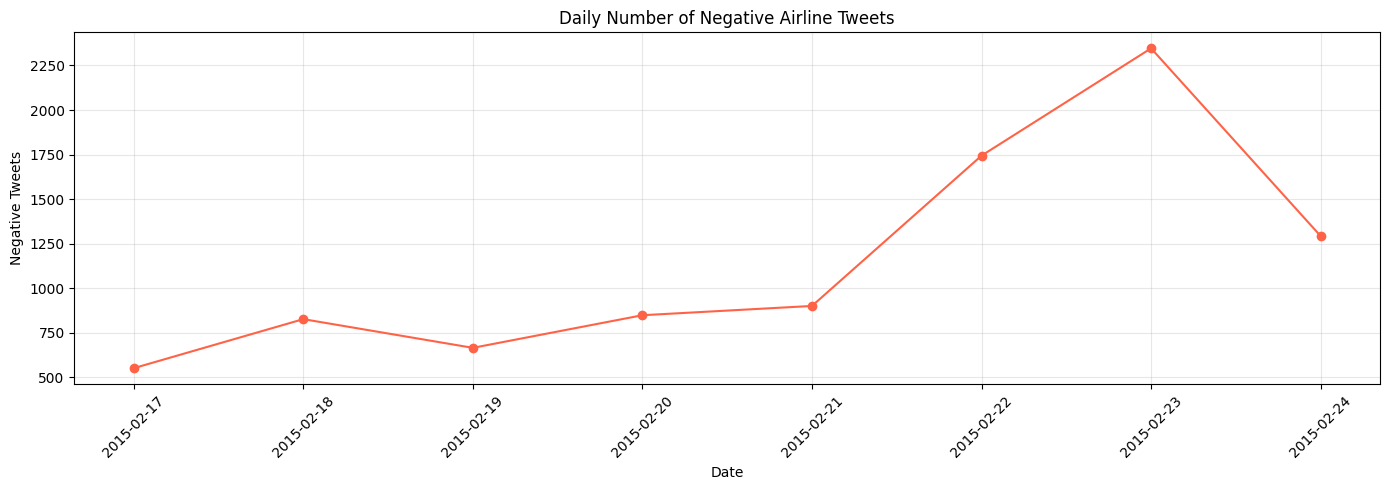

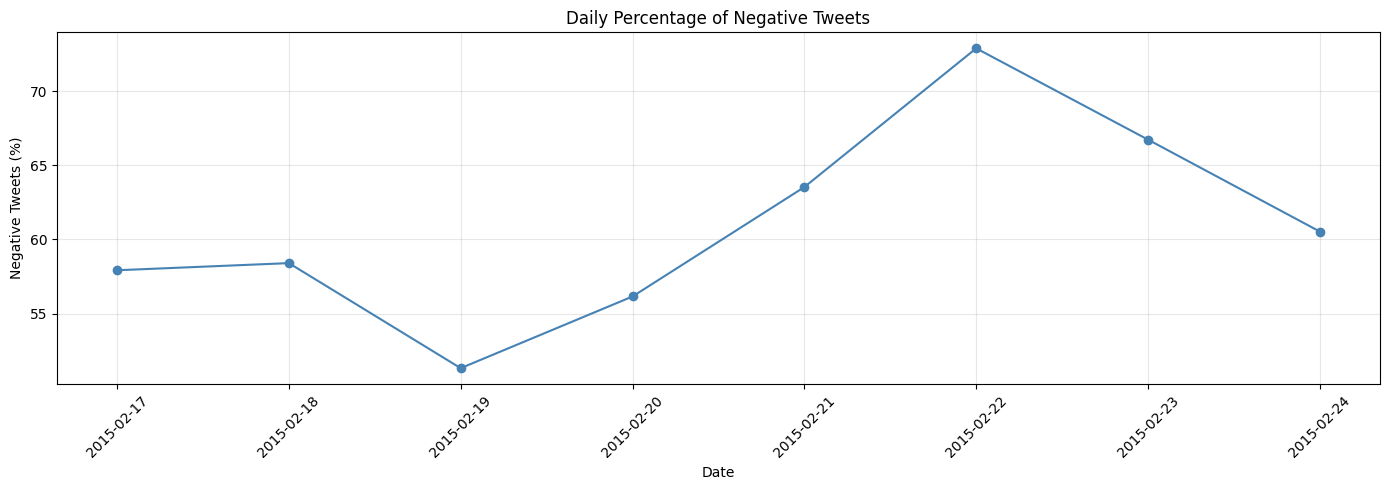

Date with the highest number of negative tweets: 2015-02-23
Number of negative tweets on that date: 2346
Negative share on that date: 66.74 %


In [34]:
# Q15: Negative Sentiment Over Time

# Check timestamp column
if 'tweet_created' not in df.columns:
    raise ValueError("tweet_created column not found.")

# Create a separate dataframe
time_df = df.copy()

# Convert tweet timestamps into datetime
time_df['tweet_created'] = pd.to_datetime(
    time_df['tweet_created'],
    errors='coerce',
    utc=True
)

# Remove invalid timestamps
time_df = time_df.dropna(
    subset=['tweet_created']
).copy()

# Extract date
time_df['Date'] = time_df['tweet_created'].dt.date

# Mark negative tweets
time_df['Is Negative'] = (
    time_df['airline_sentiment'].str.lower() == 'negative'
)

# Calculate daily negative tweets
daily_negative = time_df.groupby('Date').agg(
    Total_Tweets=('text', 'count'),
    Negative_Tweets=('Is Negative', 'sum')
)

# Calculate daily negative percentage
daily_negative['Negative Share (%)'] = (
    daily_negative['Negative_Tweets']
    / daily_negative['Total_Tweets']
) * 100

print("Daily Sentiment Summary:")
display(daily_negative.head(15))

# Plot daily negative tweet counts
plt.figure(figsize=(14, 5))

plt.plot(
    daily_negative.index,
    daily_negative['Negative_Tweets'],
    marker='o',
    color='tomato'
)

plt.title('Daily Number of Negative Airline Tweets')
plt.xlabel('Date')
plt.ylabel('Negative Tweets')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot daily negative percentage
plt.figure(figsize=(14, 5))

plt.plot(
    daily_negative.index,
    daily_negative['Negative Share (%)'],
    marker='o',
    color='steelblue'
)

plt.title('Daily Percentage of Negative Tweets')
plt.xlabel('Date')
plt.ylabel('Negative Tweets (%)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Identify highest negative tweet day
peak_day = daily_negative['Negative_Tweets'].idxmax()

print("Date with the highest number of negative tweets:", peak_day)

print(
    "Number of negative tweets on that date:",
    daily_negative.loc[peak_day, 'Negative_Tweets']
)

print(
    "Negative share on that date:",
    round(
        daily_negative.loc[peak_day, 'Negative Share (%)'],
        2
    ),
    "%"
)

## 16.

TOP 20 TWEETS REQUIRING ATTENTION:


,airline,text,negativereason,Severity,retweet_count,Priority Score,Response Priority
11596,US Airways,@USAirways 5 hr flight delay and a delay when ...,Late Flight,4,44,12.806662,Urgent
12680,American,@AmericanAir Cancelled Flight my flight saying...,Cancelled Flight,5,5,12.791759,Urgent
12681,American,@AmericanAir Again you guys are a huge joke an...,Cancelled Flight,5,4,12.609438,Urgent
12678,American,@AmericanAir This is getting a bit ridiculous ...,Cancelled Flight,5,4,12.609438,Urgent
11388,US Airways,@USAirways @DRVRugby team is back home but lu...,Damaged Luggage,5,4,12.609438,Urgent
6485,Southwest,@SouthwestAir I have had 4 flights Cancelled F...,Cancelled Flight,5,3,12.386294,Urgent
8209,Delta,@JetBlue what's going on with flight 669 and h...,Cancelled Flight,5,2,12.098612,Urgent
1107,United,"@united Oh, we are sure it's not planned, but ...",Cancelled Flight,5,2,12.098612,Urgent
2664,United,"@united first you lost all my bags, now you Ca...",Cancelled Flight,5,2,12.098612,Urgent
5226,Southwest,@SouthwestAir flight to PHL from FLL Cancelled...,Cancelled Flight,5,2,12.098612,Urgent



Tweets by Response Priority:


,count
Response Priority,
Urgent,13
High,3472
Medium,4341
Low,1352


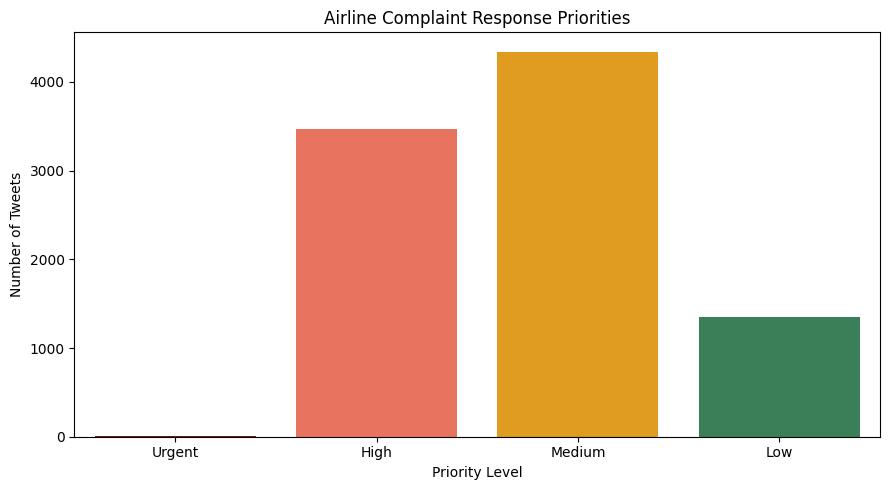


Priority Distribution by Airline:


Response Priority,Urgent,High,Medium,Low
airline,,,,
American,3,684,1044,229
Delta,1,386,373,195
Southwest,4,460,537,185
US Airways,2,807,1160,294
United,3,1083,1123,424
Virgin America,0,52,104,25


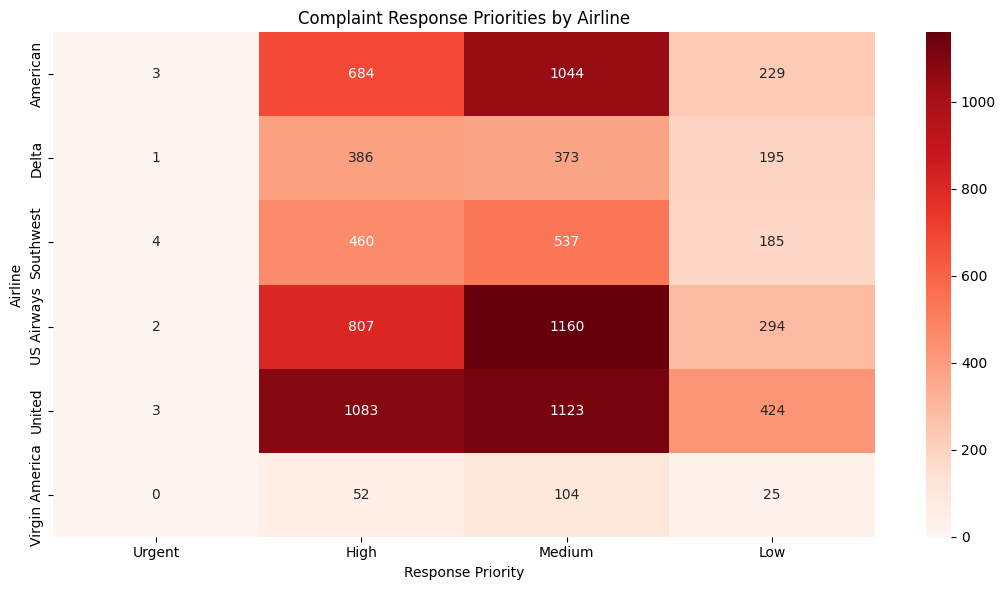

In [35]:
# Q16: Prioritize Negative Tweets

# Select negative tweets
priority_df = df[
    df['airline_sentiment'].str.lower() == 'negative'
].copy()

# Define complaint severity scores
def get_severity(reason):

    reason = str(reason).lower()

    # High priority operational problems
    if any(word in reason for word in [
        'flight cancellation',
        'cancelled flight',
        'cancel',
        'lost luggage',
        'damaged luggage'
    ]):
        return 5

    # Significant operational problems
    elif any(word in reason for word in [
        'late flight',
        'long lines',
        'bad flight'
    ]):
        return 4

    # Customer service problems
    elif any(word in reason for word in [
        'customer service',
        'flight attendant',
        'booking'
    ]):
        return 3

    else:
        return 2


# Apply severity score
if 'negativereason' in priority_df.columns:

    priority_df['Severity'] = (
        priority_df['negativereason'].apply(get_severity)
    )

else:

    priority_df['Severity'] = 2


# Use retweet count to measure public attention
if 'retweet_count' in priority_df.columns:

    priority_df['Retweet Score'] = (
        np.log1p(priority_df['retweet_count'])
    )

else:

    priority_df['Retweet Score'] = 0


# Use label confidence where available
if 'airline_sentiment_confidence' in priority_df.columns:

    priority_df['Confidence'] = (
        priority_df['airline_sentiment_confidence'].fillna(0)
    )

else:

    priority_df['Confidence'] = 0.5


# Calculate priority score
priority_df['Priority Score'] = (
    priority_df['Severity'] * 2
    + priority_df['Retweet Score']
    + priority_df['Confidence']
)


# Assign response categories
def assign_priority(score):

    if score >= 12:
        return 'Urgent'

    elif score >= 9:
        return 'High'

    elif score >= 6:
        return 'Medium'

    else:
        return 'Low'


priority_df['Response Priority'] = (
    priority_df['Priority Score'].apply(assign_priority)
)


# Sort tweets by priority
priority_df = priority_df.sort_values(
    'Priority Score',
    ascending=False
)

# Display top 20 complaints
columns_to_show = [
    'airline',
    'text',
    'negativereason',
    'Severity',
    'retweet_count',
    'Priority Score',
    'Response Priority'
]

# Only display columns available in dataset
columns_to_show = [
    col for col in columns_to_show
    if col in priority_df.columns
]

print("TOP 20 TWEETS REQUIRING ATTENTION:")

display(
    priority_df[columns_to_show].head(20)
)


# Count tweets by priority
priority_counts = priority_df[
    'Response Priority'
].value_counts().reindex(
    ['Urgent', 'High', 'Medium', 'Low'],
    fill_value=0
)

print("\nTweets by Response Priority:")
display(priority_counts)


# Visualize priorities
plt.figure(figsize=(9, 5))

sns.barplot(
    x=priority_counts.index,
    y=priority_counts.values,
    hue=priority_counts.index,
    palette=['darkred', 'tomato', 'orange', 'seagreen'],
    legend=False
)

plt.title('Airline Complaint Response Priorities')
plt.xlabel('Priority Level')
plt.ylabel('Number of Tweets')

plt.tight_layout()
plt.show()


# Compare priorities across airlines
priority_airline = pd.crosstab(
    priority_df['airline'],
    priority_df['Response Priority']
)

priority_airline = priority_airline.reindex(
    columns=['Urgent', 'High', 'Medium', 'Low'],
    fill_value=0
)

print("\nPriority Distribution by Airline:")
display(priority_airline)

plt.figure(figsize=(11, 6))

sns.heatmap(
    priority_airline,
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.title('Complaint Response Priorities by Airline')
plt.xlabel('Response Priority')
plt.ylabel('Airline')

plt.tight_layout()
plt.show()

# Part E

## 17.

DATASET OVERVIEW
Total Tweets: 14640
Total Airlines: 6

Tweets by Airline:


,count
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504



Sentiment Distribution:


,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


,proportion
airline_sentiment,
negative,62.69
neutral,21.17
positive,16.14


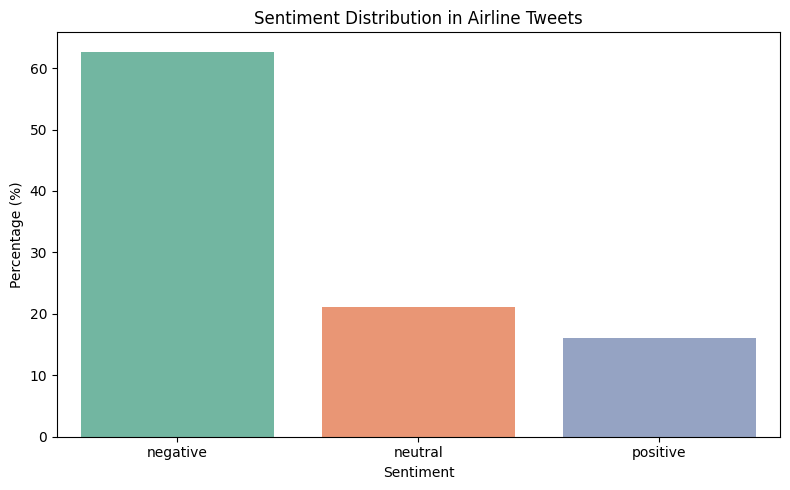

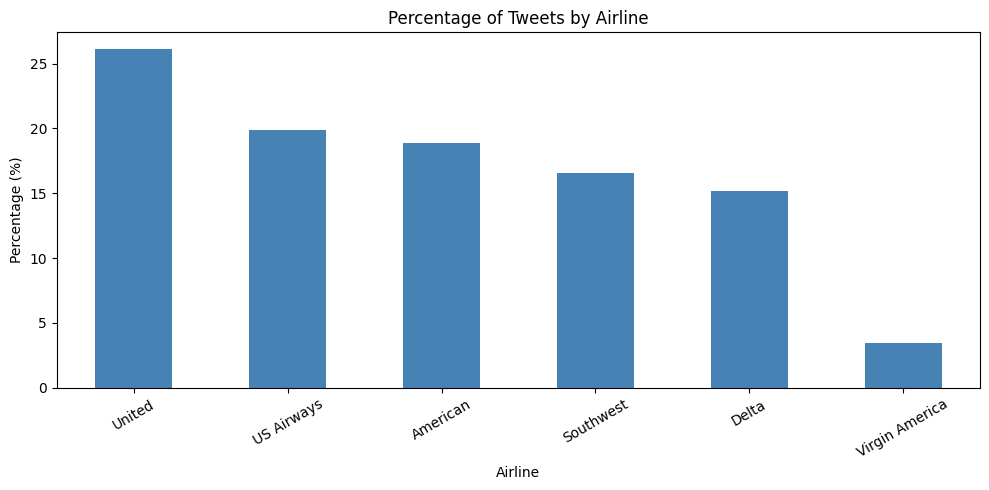

,Dataset Limitation,Possible Effect
0,Twitter users are not representative of all pa...,Results may not represent all customers
1,Customers with strong emotions may tweet more ...,Negative experiences may be overrepresented
2,Some passengers do not use social media,Offline complaints are missing
3,Airlines have different numbers of tweets,Airline comparisons may be unfair
4,Tweets contain sarcasm and informal language,Sentiment predictions may be inaccurate
5,The dataset comes from a short period in 2015,Findings may not reflect current airline perfo...


In [36]:
# Q17: Dataset Limitations and Sampling Bias

print("DATASET OVERVIEW")

print("Total Tweets:", len(df))
print("Total Airlines:", df['airline'].nunique())

print("\nTweets by Airline:")
display(df['airline'].value_counts())

print("\nSentiment Distribution:")
display(df['airline_sentiment'].value_counts())

# Calculate sentiment percentages
sentiment_percentages = (
    df['airline_sentiment']
    .value_counts(normalize=True) * 100
)

display(sentiment_percentages.round(2))

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_percentages.index,
    y=sentiment_percentages.values,
    hue=sentiment_percentages.index,
    palette='Set2',
    legend=False
)

plt.title("Sentiment Distribution in Airline Tweets")
plt.xlabel("Sentiment")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()


# Calculate airline tweet distribution
airline_percentages = (
    df['airline'].value_counts(normalize=True) * 100
)

plt.figure(figsize=(10, 5))

airline_percentages.plot(
    kind='bar',
    color='steelblue'
)

plt.title("Percentage of Tweets by Airline")
plt.xlabel("Airline")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Display limitations
limitations = pd.DataFrame({
    'Dataset Limitation': [
        'Twitter users are not representative of all passengers',
        'Customers with strong emotions may tweet more often',
        'Some passengers do not use social media',
        'Airlines have different numbers of tweets',
        'Tweets contain sarcasm and informal language',
        'The dataset comes from a short period in 2015'
    ],
    'Possible Effect': [
        'Results may not represent all customers',
        'Negative experiences may be overrepresented',
        'Offline complaints are missing',
        'Airline comparisons may be unfair',
        'Sentiment predictions may be inaccurate',
        'Findings may not reflect current airline performance'
    ]
})

display(limitations)

## 18.

Years Available in Dataset:


,count
Year,
2015,14640



Date Range:
Start: 2015-02-17 07:36:05+00:00
End: 2015-02-24 19:53:37+00:00

Historical Sentiment Distribution by Airline:


airline_sentiment,negative,neutral,positive
airline,,,
American,71.04,16.78,12.18
Delta,42.98,32.54,24.48
Southwest,49.01,27.44,23.55
US Airways,77.69,13.08,9.23
United,68.89,18.24,12.87
Virgin America,35.91,33.93,30.16


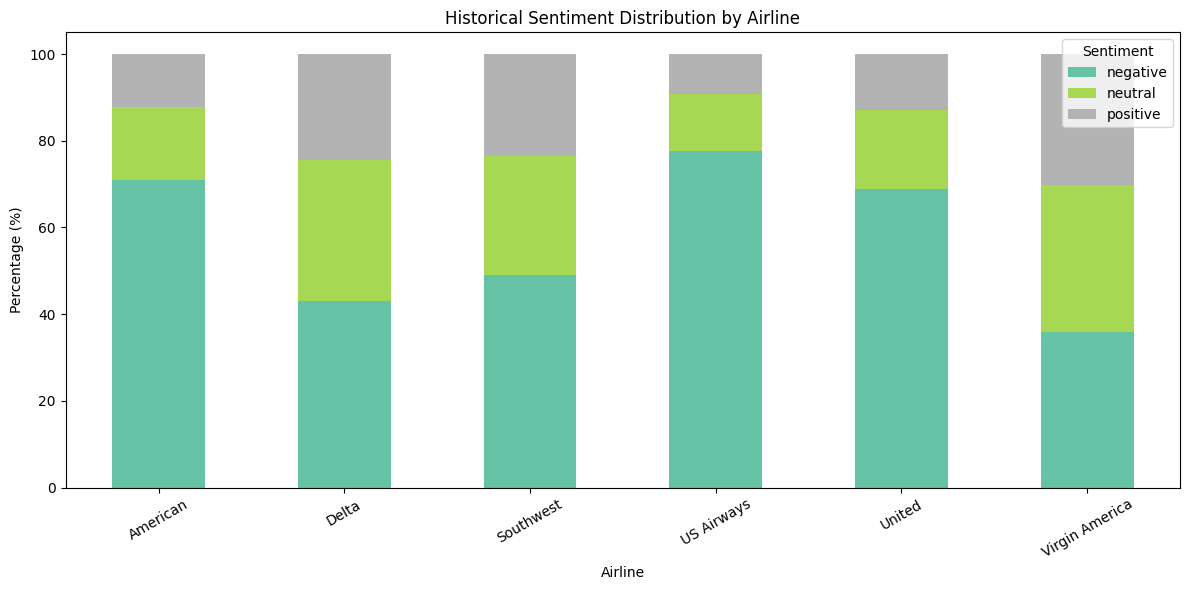

,Finding,Expected Change
0,Most frequent complaint words,New customer concerns and vocabulary may appear
1,Airline customer service ranking,Airline performance and customer expectations ...
2,Negative sentiment percentages,Customer experiences may improve or deteriorate
3,Common operational problems,Technology and airline procedures may change
4,Sentiment model accuracy,Modern language and new expressions may affect...
5,Complaint response priorities,New operational risks may require different pr...


In [37]:
# Q18: Historical Dataset Analysis

# Convert tweet dates
historical_df = df.copy()

historical_df['tweet_created'] = pd.to_datetime(
    historical_df['tweet_created'],
    errors='coerce',
    utc=True
)

historical_df = historical_df.dropna(
    subset=['tweet_created']
)

# Extract year and month
historical_df['Year'] = (
    historical_df['tweet_created'].dt.year
)

historical_df['Month'] = (
    historical_df['tweet_created'].dt.month
)

print("Years Available in Dataset:")
display(historical_df['Year'].value_counts())

print("\nDate Range:")
print("Start:", historical_df['tweet_created'].min())
print("End:", historical_df['tweet_created'].max())


# Sentiment distribution by airline
historical_comparison = pd.crosstab(
    historical_df['airline'],
    historical_df['airline_sentiment'],
    normalize='index'
) * 100

print("\nHistorical Sentiment Distribution by Airline:")
display(historical_comparison.round(2))


# Visualize
historical_comparison.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='Set2'
)

plt.title("Historical Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Percentage (%)")
plt.legend(title="Sentiment")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Findings that may change over time
future_changes = pd.DataFrame({
    'Finding': [
        'Most frequent complaint words',
        'Airline customer service ranking',
        'Negative sentiment percentages',
        'Common operational problems',
        'Sentiment model accuracy',
        'Complaint response priorities'
    ],
    'Expected Change': [
        'New customer concerns and vocabulary may appear',
        'Airline performance and customer expectations may change',
        'Customer experiences may improve or deteriorate',
        'Technology and airline procedures may change',
        'Modern language and new expressions may affect predictions',
        'New operational risks may require different priorities'
    ]
})

display(future_changes)

## 19.

In [38]:
# Q19: Automated vs Manual Sentiment Analysis

# Calculate VADER accuracy using Part C results
if 'sentiment_df' in globals():

    actual = sentiment_df['airline_sentiment']
    predicted = sentiment_df['vader_sentiment']

    automated_accuracy = accuracy_score(
        actual,
        predicted
    ) * 100

    print("VADER Accuracy:", round(automated_accuracy, 2), "%")

    # Calculate per-class performance
    print("\nClass Performance:")

    print(
        classification_report(
            actual,
            predicted,
            zero_division=0
        )
    )

else:
    automated_accuracy = None
    print("Run Question 9 before Question 19.")


# Strengths and limitations
evaluation = pd.DataFrame({
    'Automated Analysis Strengths': [
        'Processes thousands of tweets quickly',
        'Provides consistent sentiment scoring',
        'Identifies complaint patterns',
        'Can monitor tweets continuously',
        'Reduces repetitive manual work'
    ],

    'Automated Analysis Limitations': [
        'Can misunderstand sarcasm',
        'May mishandle negation',
        'Struggles with mixed emotions',
        'May misunderstand airline terminology',
        'Cannot fully understand customer context'
    ]
})

display(evaluation)


# Recommendation
print("\nFINAL RECOMMENDATION")

print("""
The airline should NOT completely replace the manual tweet-reading team.

Instead, it should use a hybrid approach.

1. Automated tools should process incoming tweets.
2. High-priority negative tweets should be flagged immediately.
3. Human analysts should review ambiguous and complex tweets.
4. Human feedback should be used to improve the sentiment model.
5. The system should be evaluated regularly using manually labelled tweets.

Automation can reduce response time, while human analysts provide
context, judgment and understanding of customer emotions.
""")

VADER Accuracy: 48.99 %

Class Performance:
              precision    recall  f1-score   support

    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099
    positive       0.28      0.91      0.43      2363

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640



,Automated Analysis Strengths,Automated Analysis Limitations
0,Processes thousands of tweets quickly,Can misunderstand sarcasm
1,Provides consistent sentiment scoring,May mishandle negation
2,Identifies complaint patterns,Struggles with mixed emotions
3,Can monitor tweets continuously,May misunderstand airline terminology
4,Reduces repetitive manual work,Cannot fully understand customer context



FINAL RECOMMENDATION

The airline should NOT completely replace the manual tweet-reading team.

Instead, it should use a hybrid approach.

1. Automated tools should process incoming tweets.
2. High-priority negative tweets should be flagged immediately.
3. Human analysts should review ambiguous and complex tweets.
4. Human feedback should be used to improve the sentiment model.
5. The system should be evaluated regularly using manually labelled tweets.

Automation can reduce response time, while human analysts provide
context, judgment and understanding of customer emotions.



I recommend using automated sentiment analysis as a support system rather than a complete replacement for manual tweet reading.

VADER can process large numbers of tweets quickly and identify common sentiment patterns. However, Part C demonstrates that it can misunderstand sarcasm, negation, mixed feelings and airline-specific terminology.

A hybrid approach would allow the airline to respond faster while retaining human judgment for complicated complaints

# Part F

## Insight 1 – Are complaints concentrated around particular hours?

,Total_Tweets,Negative_Tweets,Negative Percentage
Hour,,,
0,734,463,63.08
1,754,451,59.81
2,751,477,63.52
3,675,482,71.41
4,602,389,64.62
5,430,291,67.67
6,292,215,73.63
7,193,142,73.58
8,131,97,74.05


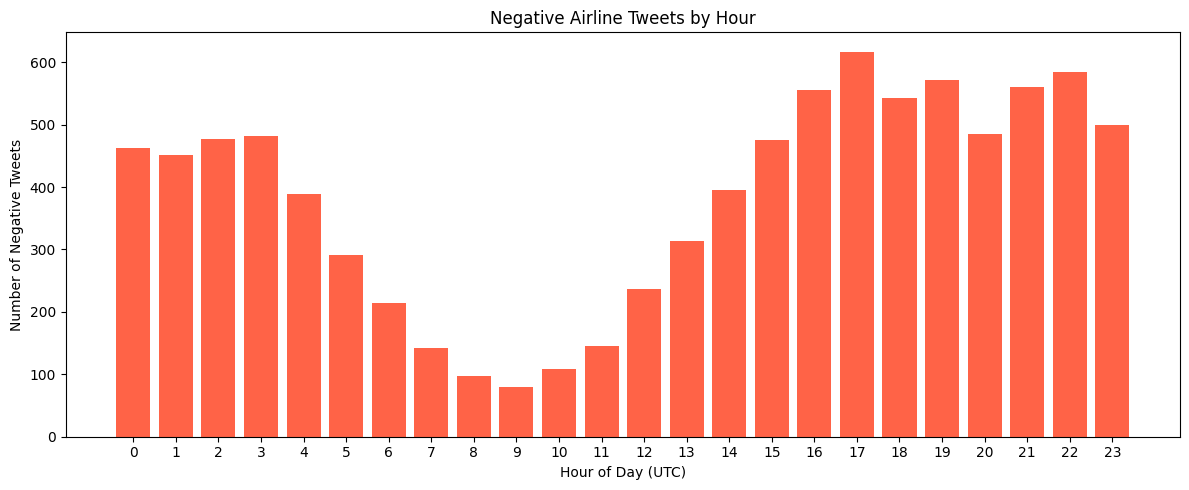

Hour with highest negative tweet volume: 17
Negative tweets during this hour: 617
Negative percentage: 60.91 %


In [39]:
# PART F - INSIGHT 1: Complaint Activity by Hour

hour_df = df.copy()

hour_df['tweet_created'] = pd.to_datetime(
    hour_df['tweet_created'],
    errors='coerce',
    utc=True
)

hour_df = hour_df.dropna(
    subset=['tweet_created']
)

hour_df['Hour'] = (
    hour_df['tweet_created'].dt.hour
)

hour_df['Negative'] = (
    hour_df['airline_sentiment'] == 'negative'
)

hour_analysis = hour_df.groupby('Hour').agg(
    Total_Tweets=('text', 'count'),
    Negative_Tweets=('Negative', 'sum')
)

hour_analysis['Negative Percentage'] = (
    hour_analysis['Negative_Tweets']
    / hour_analysis['Total_Tweets']
) * 100

display(hour_analysis.round(2))

# Plot hourly complaints
plt.figure(figsize=(12, 5))

plt.bar(
    hour_analysis.index,
    hour_analysis['Negative_Tweets'],
    color='tomato'
)

plt.title('Negative Airline Tweets by Hour')
plt.xlabel('Hour of Day (UTC)')
plt.ylabel('Number of Negative Tweets')
plt.xticks(range(24))
plt.tight_layout()
plt.show()

# Find peak hour
peak_hour = hour_analysis['Negative_Tweets'].idxmax()

print("Hour with highest negative tweet volume:", peak_hour)

print(
    "Negative tweets during this hour:",
    hour_analysis.loc[peak_hour, 'Negative_Tweets']
)

print(
    "Negative percentage:",
    round(
        hour_analysis.loc[peak_hour, 'Negative Percentage'],
        2
    ),
    "%"
)

# Insight 2 – Does tweet length reveal customer dissatisfaction?


Tweet Length Statistics:


,mean,median,min,max,count
airline_sentiment,,,,,
negative,19.69,21.0,2,36,9178
neutral,14.41,14.0,2,31,3099
positive,14.01,14.0,2,31,2363


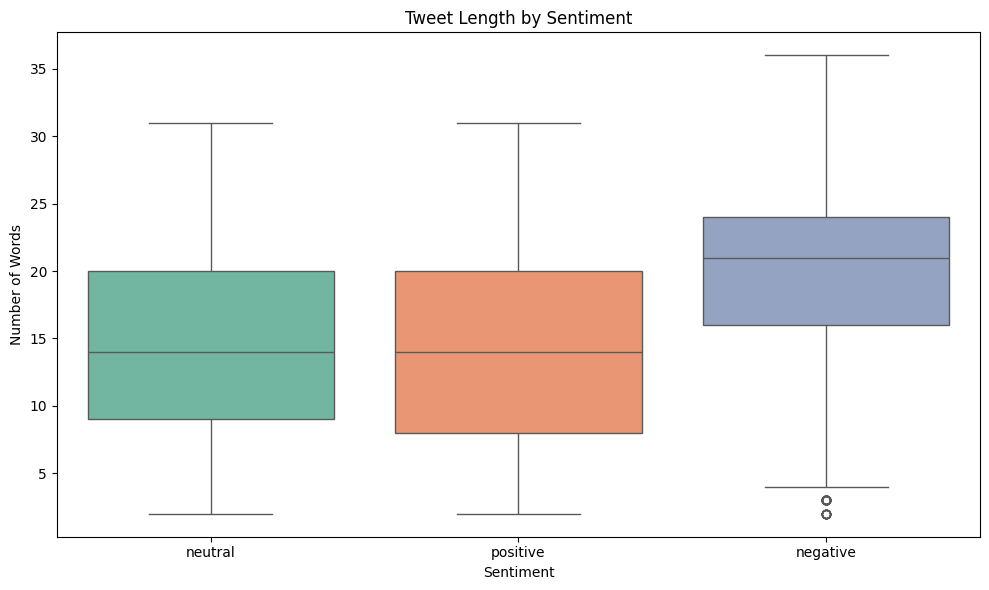


Average Tweet Length:


,Tweet Length
airline_sentiment,
negative,19.69
neutral,14.41
positive,14.01



Sentiment with longest average tweets: negative


In [40]:
# PART F - INSIGHT 2: Tweet Length Analysis

length_df = df.copy()

# Calculate tweet length
length_df['Tweet Length'] = (
    length_df['text'].astype(str).apply(
        lambda x: len(x.split())
    )
)

# Summary statistics
length_summary = length_df.groupby(
    'airline_sentiment'
)['Tweet Length'].agg(
    ['mean', 'median', 'min', 'max', 'count']
)

print("Tweet Length Statistics:")
display(length_summary.round(2))

# Box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=length_df,
    x='airline_sentiment',
    y='Tweet Length',
    hue='airline_sentiment',
    palette='Set2',
    legend=False
)

plt.title('Tweet Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Words')
plt.tight_layout()
plt.show()

# Compare average lengths
average_lengths = length_df.groupby(
    'airline_sentiment'
)['Tweet Length'].mean()

print("\nAverage Tweet Length:")
display(average_lengths.round(2))

print(
    "\nSentiment with longest average tweets:",
    average_lengths.idxmax()
)

#Insight 3 – Which complaint reasons dominate each airline?


Complaint Reason Frequencies:


,Frequency
negativereason,
Customer Service Issue,2910
Late Flight,1665
Can't Tell,1190
Cancelled Flight,847
Lost Luggage,724
Bad Flight,580
Flight Booking Problems,529
Flight Attendant Complaints,481
longlines,178



Complaint Reason Percentages:


,count
negativereason,
Customer Service Issue,31.71
Late Flight,18.14
Can't Tell,12.97
Cancelled Flight,9.23
Lost Luggage,7.89
Bad Flight,6.32
Flight Booking Problems,5.76
Flight Attendant Complaints,5.24
longlines,1.94


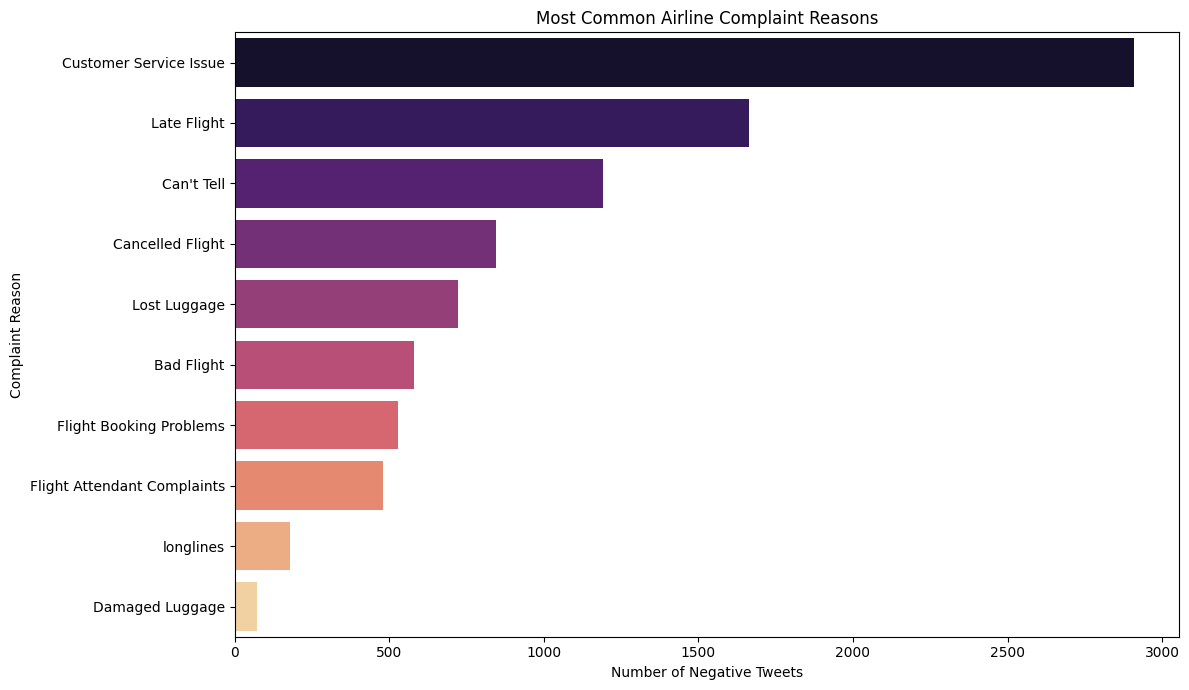


Top Three Complaint Reasons:


,count
negativereason,
Customer Service Issue,2910
Late Flight,1665
Can't Tell,1190



Percentage represented by top three: 62.81 %


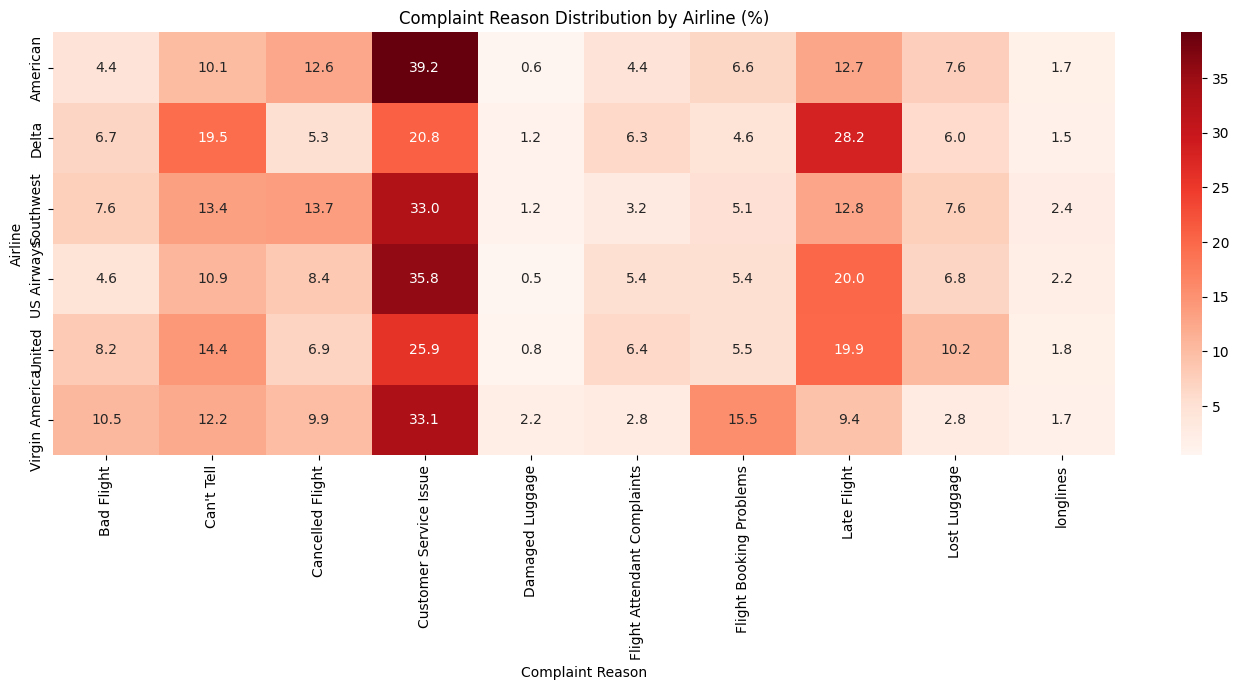

In [41]:
# PART F - INSIGHT 3: Complaint Concentration

if 'negativereason' in df.columns:

    reason_df = df[
        df['airline_sentiment'] == 'negative'
    ].dropna(
        subset=['negativereason']
    ).copy()

    # Count complaint reasons
    reason_counts = reason_df[
        'negativereason'
    ].value_counts()

    print("Complaint Reason Frequencies:")
    display(reason_counts.to_frame('Frequency'))

    # Calculate percentage
    reason_percentages = (
        reason_counts / reason_counts.sum()
    ) * 100

    print("\nComplaint Reason Percentages:")
    display(reason_percentages.round(2))

    # Visualize
    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=reason_counts.values,
        y=reason_counts.index,
        hue=reason_counts.index,
        palette='magma',
        legend=False
    )

    plt.title('Most Common Airline Complaint Reasons')
    plt.xlabel('Number of Negative Tweets')
    plt.ylabel('Complaint Reason')
    plt.tight_layout()
    plt.show()

    # Top three complaint reasons
    top_three = reason_counts.head(3)

    print("\nTop Three Complaint Reasons:")
    display(top_three)

    print(
        "\nPercentage represented by top three:",
        round(
            top_three.sum() / reason_counts.sum() * 100,
            2
        ),
        "%"
    )

    # Compare reasons across airlines
    airline_reasons = pd.crosstab(
        reason_df['airline'],
        reason_df['negativereason'],
        normalize='index'
    ) * 100

    plt.figure(figsize=(14, 7))

    sns.heatmap(
        airline_reasons,
        cmap='Reds',
        annot=True,
        fmt='.1f'
    )

    plt.title('Complaint Reason Distribution by Airline (%)')
    plt.xlabel('Complaint Reason')
    plt.ylabel('Airline')
    plt.tight_layout()
    plt.show()

else:

    print("The dataset does not contain a negativereason column.")

# Insight 4 – Which airline receives the most positive feedback?


Positive Feedback by Airline:


,Positive Tweets,Total Tweets,Positive Share (%)
airline,,,
Virgin America,152,504,30.16
Delta,544,2222,24.48
Southwest,570,2420,23.55
United,492,3822,12.87
American,336,2759,12.18
US Airways,269,2913,9.23


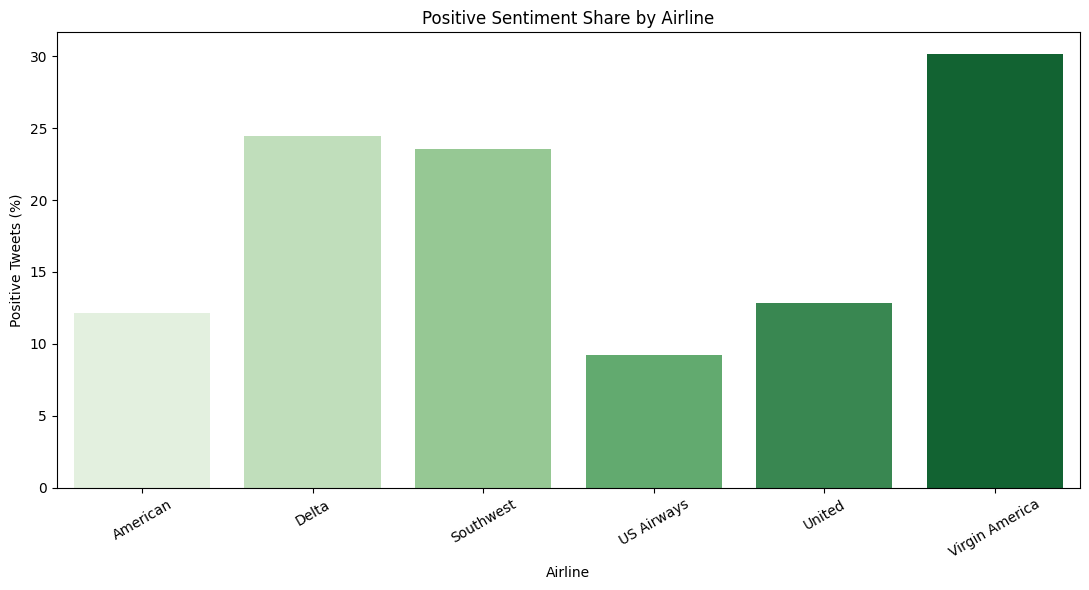


Airline with highest positive sentiment share: Virgin America


In [42]:
# PART F - INSIGHT 4: Positive Customer Feedback

positive_df = df[
    df['airline_sentiment'] == 'positive'
]

positive_counts = positive_df[
    'airline'
].value_counts()

total_counts = df[
    'airline'
].value_counts()

positive_share = (
    positive_counts / total_counts
) * 100

positive_comparison = pd.DataFrame({
    'Positive Tweets': positive_counts,
    'Total Tweets': total_counts,
    'Positive Share (%)': positive_share
}).fillna(0)

print("Positive Feedback by Airline:")
display(
    positive_comparison.sort_values(
        'Positive Share (%)',
        ascending=False
    ).round(2)
)

# Plot positive shares
plt.figure(figsize=(11, 6))

sns.barplot(
    data=positive_comparison.reset_index(),
    x='airline',
    y='Positive Share (%)',
    hue='airline',
    palette='Greens',
    legend=False
)

plt.title('Positive Sentiment Share by Airline')
plt.xlabel('Airline')
plt.ylabel('Positive Tweets (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(
    "\nAirline with highest positive sentiment share:",
    positive_comparison['Positive Share (%)'].idxmax()
)